# MATH840 Final project, Session 1

Tuesday 3 November 2026. Submit `SURNAME_project.csv` on Moodle by **11:30**.

You work as a data scientist at an energy company. You have the hourly electricity generation of its
portfolio, with the weather, up to midnight on 27 October 2026. Your task is to forecast the next 48
hours, hour by hour, with a 95% prediction interval.

This notebook loads the data, defines the scores, computes the benchmark and writes the submission file.
You choose and build the model yourself.

The submission cell starts from the benchmark. If you run the notebook from top to bottom first, you
will have a valid file within five minutes, and you can use the rest of the session to beat it.

## 0. Setup

Download `train.csv` and `weather_forecast.csv` from Moodle. In Colab, the next cell asks you to upload
them. On your own machine, put them in the same folder as the notebook.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (11, 4), "axes.grid": True, "grid.alpha": 0.3})
pd.set_option("display.width", 120, "display.precision", 3)

SURNAME = "LUKIANETS"   # <-- for your submission file name

if not SURNAME.strip():
    raise ValueError("Set SURNAME before running the rest.")

In [2]:
NEEDED = ["train.csv", "weather_forecast.csv"]

if not all(Path(f).exists() for f in NEEDED):
    try:
        from google.colab import files
        files.upload()                       # choose both files at once
    except ImportError:
        raise FileNotFoundError(f"Put {NEEDED} next to this notebook.")

data = pd.read_csv("train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv("weather_forecast.csv", parse_dates=["ds"])

H = 48                                       # hours to forecast
M = 24                                       # the benchmark's season: one day
FUTURE = weather_fc["ds"]

assert len(FUTURE) == H and FUTURE.iloc[0] == data["ds"].iloc[-1] + pd.Timedelta(hours=1)
print(f"history: {len(data)} hours, {data['ds'].min()} to {data['ds'].max()}")
print(f"you are forecasting: {FUTURE.iloc[0]} to {FUTURE.iloc[-1]}")
data.tail()

history: 33480 hours, 2023-01-01 01:00:00 to 2026-10-27 00:00:00
you are forecasting: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.259
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.259
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.268
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.268
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.268


### The data

| Column | Meaning |
|---|---|
| `ds` | the hour |
| `y` | electricity generated in that hour; this is what you forecast |
| `cloud_cover` | from 0 (clear) to 1 (overcast), in steps of 0.25 |
| `temperature` | °C |
| `wind_speed` | m/s |
| `pressure` | mm Hg |
| `humidity` | % |
| `daylight` | 1 while the sun is above the horizon |
| `air_density` | kg/m³ |

`train.csv` has the weather as it was. `weather_forecast.csv` has a forecast for the 48 hours you
predict, of the kind a weather service issues. Its errors grow from the first day to the second.

## 1. How you are scored

Your file gets three scores on the 48 hidden hours, and lower is better for each. RMSE measures the
point forecast in the units of `y`, and MAPE measures it in percent of the actual value. The Winkler
score measures the 95% interval: its width, plus 40 times ($2/\alpha$) the distance by which the actual
value falls outside it.

The benchmark is a seasonal naive forecast with a daily season. Each hour of the next two days gets the
value of the same hour on the last day you have. Its 95% interval is the standard one for seasonal naive,
$\hat y \pm 1.96\,\hat\sigma\sqrt{k+1}$, where $k$ is the number of full days into the horizon.

The project description on Moodle explains the points and the leaderboard.

In [3]:
def rmse(actual, forecast) -> float:
    return float(np.sqrt(np.mean((np.asarray(actual) - np.asarray(forecast)) ** 2)))


def mape(actual, forecast) -> float:
    actual, forecast = np.asarray(actual, float), np.asarray(forecast, float)
    return float(np.mean(np.abs((actual - forecast) / actual)) * 100)


def winkler(actual, lower, upper, alpha: float = 0.05) -> float:
    actual, lower, upper = (np.asarray(a, float) for a in (actual, lower, upper))
    below = np.clip(lower - actual, 0, None)
    above = np.clip(actual - upper, 0, None)
    return float(np.mean((upper - lower) + 2 / alpha * (below + above)))


def score(actual, forecast, lower, upper) -> dict:
    inside = (np.asarray(actual) >= lower) & (np.asarray(actual) <= upper)
    return {"RMSE": rmse(actual, forecast), "MAPE": mape(actual, forecast),
            "Winkler": winkler(actual, lower, upper), "coverage": float(inside.mean())}


def snaive(history: np.ndarray, h: int = H, m: int = M):
    # The benchmark: repeat the last season, with the seasonal-naive 95% interval.
    history = np.asarray(history, float)
    point = np.array([history[-m + (i % m)] for i in range(h)])
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    k = np.arange(h) // m
    half = 1.96 * sigma * np.sqrt(k + 1)
    return point, np.clip(point - half, 0, None), point + half

### The benchmark on a validation window

You cannot score a forecast on the hidden hours, so the cell below holds back the last 48 hours of the
history, forecasts them from the hours before, and scores the result. This is a single window. You can
decide how much more validation you need.

In [4]:
y = data["y"].to_numpy(float)
past, valid = y[:-H], y[-H:]

bench = snaive(past)
results = pd.DataFrame({"seasonal naive": score(valid, *bench)}).T
results

,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.0


## 2. Your model

You can use any model or library, from the course or outside it, with or without the weather forecast.
Add your validation scores to `results`, so that they sit next to the benchmark's.

When you have chosen a model, fit it on the whole history and forecast the 48 hours after the end of
`data` in the submission cell below.

### 2.0 Setup for Section 2 (Mac: statistical and machine-learning models)

This notebook runs everything that is fast on a laptop: EDA, ETS and ARIMA on several training lengths, Prophet,
LightGBM. The foundation and neural models run in `LUKIANETS_project_colab.ipynb` on the **same 20 rolling windows**
with the same scores; their results come back as two files (`colab_bt.csv`, `colab_final.csv`) and are merged in 2.10.

**Rolling validation.** 20 windows, one forecast origin every midnight from 6 to 25 October; each window forecasts
48 hours from the data before its origin only (window 1 = the template's validation window). Scored with the
template's `score` (RMSE, MAPE, 95% Winkler) next to the template's seasonal naive, **on day 2** (hours 25–48: the
private leaderboard's hours; `PART = "all"` switches to all 48). Neighbouring windows share a day, so anything tuned
on the windows' errors (the night rule, interval widths, conformal radii) is tuned *without the scored window and its
two neighbours* (purged leave-one-window-out).

⚠️ On the windows the weather models see the weather **as it was**; in the submission they see the **forecast**,
whose errors grow on day 2: their validation is optimistic.

`QUICK = True` keeps the run to about 30 minutes with the variants that mattered in the 10-window study of 3 November
(the full ETS / ARIMA / LightGBM grids are in that run); `QUICK = False` runs the full grids (about an hour).

In [5]:
import itertools
import os
import time
import logging
os.environ["NIXTLA_ID_AS_COL"] = "true"
for name in ("transformers", "root", "cmdstanpy", "prophet", "lightning", "lightning.pytorch", "gluonts",
             "nixtla.nixtla_client", "pytorch_lightning", "neuralforecast"):
    logging.getLogger(name).setLevel(logging.ERROR)

from IPython.display import display
from scipy import signal, stats
from scipy.special import boxcox
from coreforecast.scalers import boxcox_lambda
from statsmodels.tsa.seasonal import MSTL as MSTL_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsforecast.arima import ARIMASummary, ndiffs, nsdiffs
from statsforecast.models import ARIMA, AutoARIMA, AutoETS, AutoTheta, MSTL
try:
    from dotenv import load_dotenv
    load_dotenv()                  # .env next to the notebook holds NIXTLA_API_KEY: never paste the key here
except ImportError:
    pass

dates = data["ds"].reset_index(drop=True)
FREQ = "h"
DAY = 24
WINDOWS = 20                       # rolling 48-hour windows: the SAME on the Mac and in Colab (merged later)
STEP = 24                          # hours between window origins: one origin every midnight (6-25 October)
PART = "day2"                      # the hours a choice is judged on: "day2" (hours 25-48, the private part) or "all"
LAMBDA = 0.45                      # Box-Cox lambda (Guerrero on the last 12 weeks, Section 2.2)
FM_CONTEXT = 2048                  # hours of history a foundation model reads (default)

T0 = time.time()
def elapsed():
    print(f"[{(time.time() - T0) / 60:.1f} min since the start of Section 2]")

QUICK = True                       # <-- False: the full ETS / ARIMA / Prophet / LightGBM grids (about an hour)

### 2.1 EDA

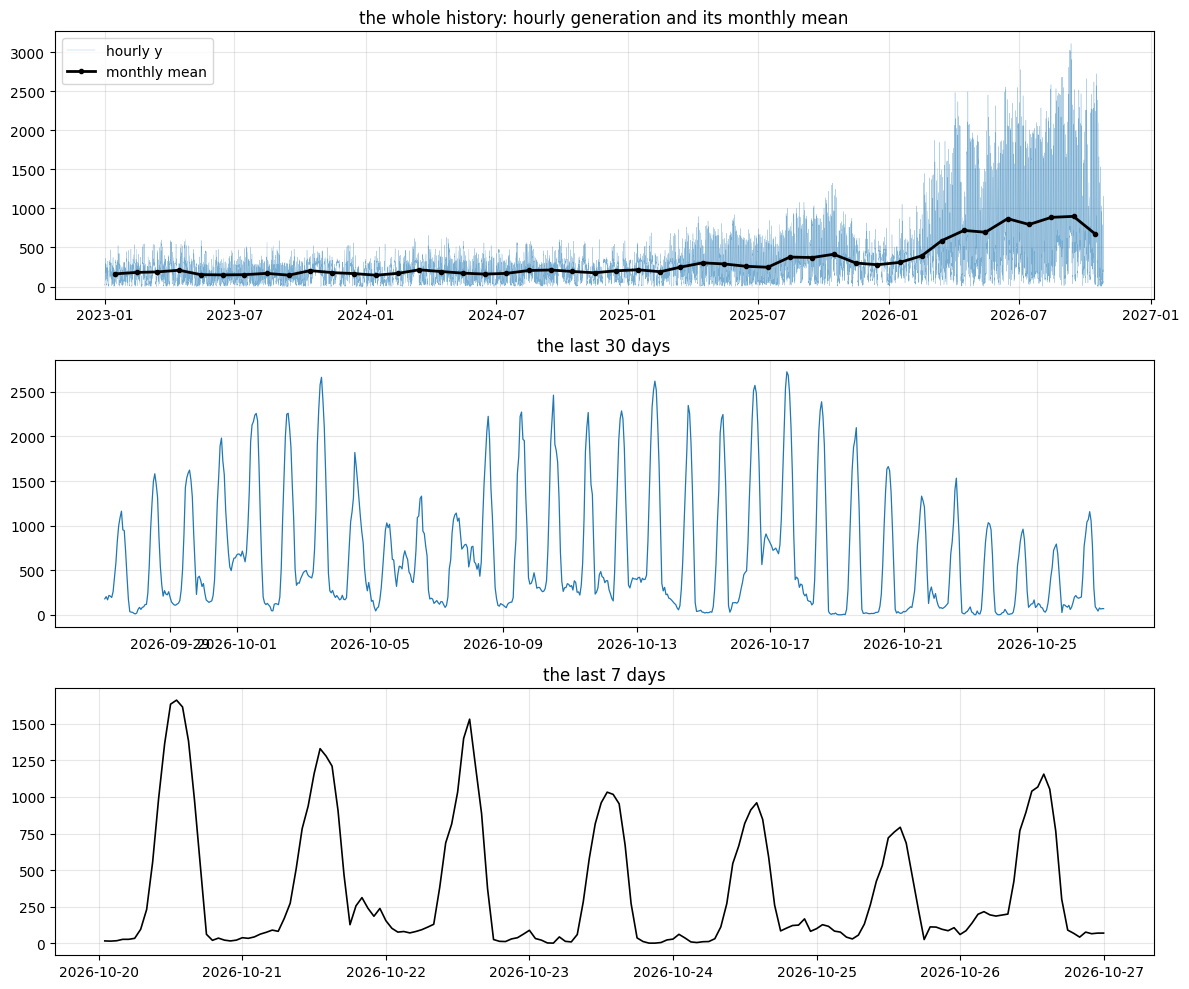

mean by year: {2023: 170.8, 2024: 183.9, 2025: 291.5, 2026: 683.8}
mean of the last 7 days, day by day: {datetime.date(2026, 10, 20): 493.0, datetime.date(2026, 10, 21): 451.0, datetime.date(2026, 10, 22): 392.0, datetime.date(2026, 10, 23): 289.0, datetime.date(2026, 10, 24): 286.0, datetime.date(2026, 10, 25): 258.0, datetime.date(2026, 10, 26): 390.0, datetime.date(2026, 10, 27): 70.0}
2023: 20-31 Oct mean 271, November mean 178
2024: 20-31 Oct mean 191, November mean 176
2025: 20-31 Oct mean 353, November mean 301


In [6]:
monthly = data.set_index("ds")["y"].resample("MS").mean()
fig, axes = plt.subplots(3, 1, figsize=(12, 10))
axes[0].plot(dates, y, lw=0.2, alpha=0.6, label="hourly y")
axes[0].plot(monthly.index + pd.Timedelta(days=14), monthly.values, color="black", lw=2, marker="o", ms=3, label="monthly mean")
axes[0].set_title("the whole history: hourly generation and its monthly mean")
axes[0].legend(loc="upper left")
axes[1].plot(dates.iloc[-30 * DAY:], y[-30 * DAY:], lw=0.9)
axes[1].set_title("the last 30 days")
axes[2].plot(dates.iloc[-7 * DAY:], y[-7 * DAY:], lw=1.2, color="black")
axes[2].set_title("the last 7 days")
plt.tight_layout()
plt.show()
print("mean by year:", data.groupby(dates.dt.year)["y"].mean().round(1).to_dict())
print("mean of the last 7 days, day by day:", data.iloc[-7 * DAY:].groupby(dates.iloc[-7 * DAY:].dt.date)["y"].mean().round(0).to_dict())
for yr in (2023, 2024, 2025):
    s = data[(dates >= f"{yr}-10-20") & (dates < f"{yr}-11-01")]
    nxt = data[(dates >= f"{yr}-11-01") & (dates < f"{yr}-12-01")]["y"].mean()
    print(f"{yr}: 20-31 Oct mean {s['y'].mean():.0f}, November mean {nxt:.0f}")

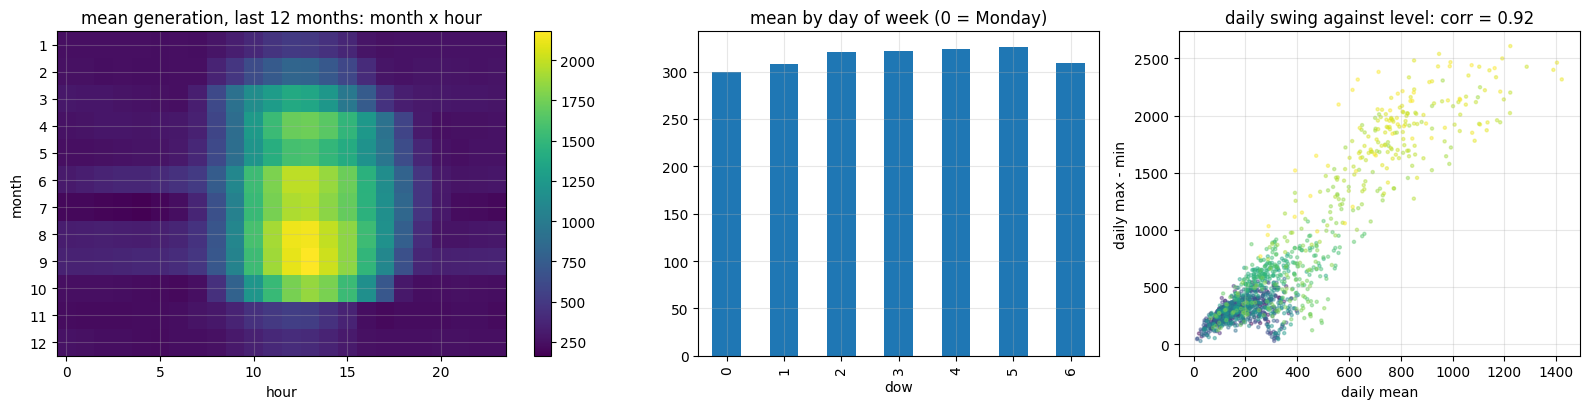

mean by day of week: {0: 299.2, 1: 308.4, 2: 321.2, 3: 322.2, 4: 323.6, 5: 326.2, 6: 309.6}


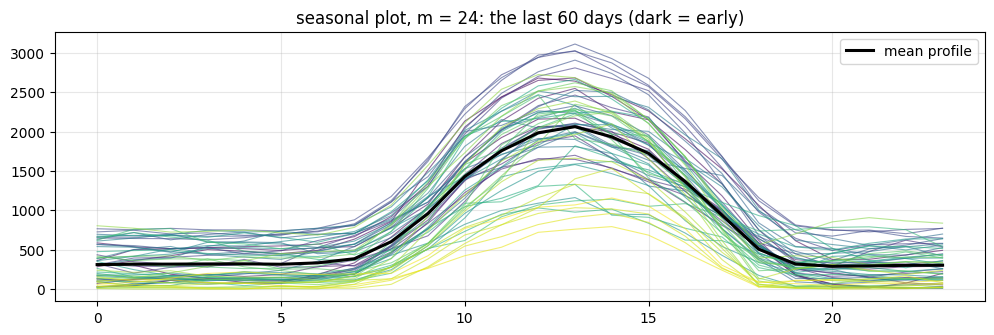

In [7]:
frame = pd.DataFrame({"y": y, "hour": dates.dt.hour, "dow": dates.dt.dayofweek, "month": dates.dt.month,
                      "day": dates.dt.normalize()})
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2), gridspec_kw={"width_ratios": [1.4, 1, 1]})
heat = frame[dates >= "2025-11-01"].pivot_table(index="month", columns="hour", values="y", aggfunc="mean")
im = axes[0].imshow(heat, aspect="auto", cmap="viridis")
axes[0].set_yticks(range(len(heat)), heat.index)
axes[0].set_xlabel("hour")
axes[0].set_ylabel("month")
axes[0].set_title("mean generation, last 12 months: month x hour")
fig.colorbar(im, ax=axes[0])
dow = frame.groupby("dow")["y"].mean()
dow.plot(kind="bar", ax=axes[1], title="mean by day of week (0 = Monday)")
daily = frame.groupby("day")["y"].agg(level="mean", swing=lambda v: v.max() - v.min())
daily = daily[frame.groupby("day").size() == 24]
axes[2].scatter(daily["level"], daily["swing"], s=5, alpha=0.4, c=np.arange(len(daily)), cmap="viridis")
axes[2].set_title(f"daily swing against level: corr = {daily['level'].corr(daily['swing']):.2f}")
axes[2].set_xlabel("daily mean")
axes[2].set_ylabel("daily max - min")
plt.tight_layout()
plt.show()
print("mean by day of week:", dow.round(1).to_dict())

last = frame.iloc[-60 * DAY:]
pivot = last.pivot_table(index="hour", columns="day", values="y")
fig, ax = plt.subplots(figsize=(12, 3.5))
for c, col in zip(plt.cm.viridis(np.linspace(0, 1, pivot.shape[1])), pivot.columns):
    ax.plot(pivot.index, pivot[col], color=c, lw=0.8, alpha=0.6)
ax.plot(pivot.index, pivot.mean(axis=1), color="black", lw=2.2, label="mean profile")
ax.set_title("seasonal plot, m = 24: the last 60 days (dark = early)")
ax.legend()
plt.show()

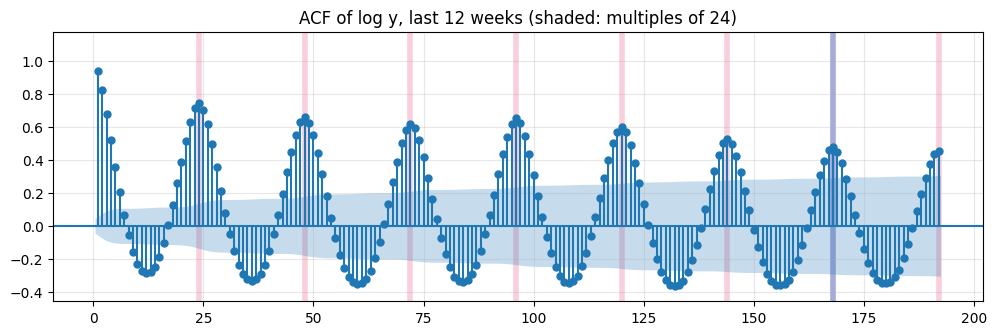

                     0       1       2       3       4        5       6        7
period (hours)  24.000  12.000  23.900  24.100  123.40  104.300  97.300  168.500
share of power   0.435   0.038   0.031   0.028    0.01    0.009   0.006    0.006


,trend F_T,season F_S (m=24),season F_S (m=168)
original,0.477,0.906,0.106
log,0.325,0.657,0.000


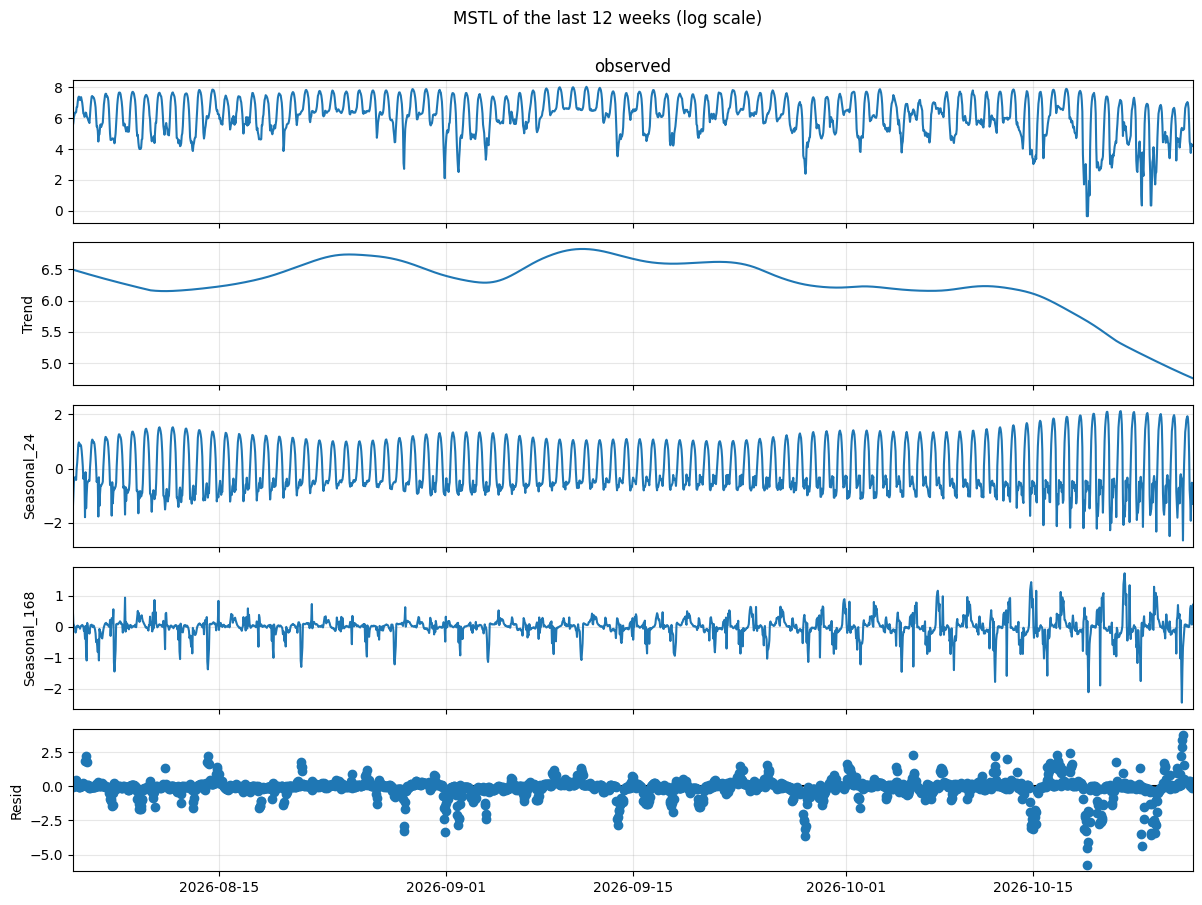

In [8]:
recent = y[-12 * 7 * DAY:]                                  # the last 12 weeks
fig, ax = plt.subplots(figsize=(12, 3.5))
plot_acf(np.log(recent), lags=8 * DAY, zero=False, ax=ax, auto_ylims=True, title="ACF of log y, last 12 weeks (shaded: multiples of 24)")
for k in range(DAY, 8 * DAY + 1, DAY):
    ax.axvline(k, color="#e64173", alpha=0.25, lw=4, zorder=0)
ax.axvline(168, color="#2a78d6", alpha=0.4, lw=4, zorder=0)
plt.show()

x = np.log(y) - pd.Series(np.log(y)).rolling(168, center=True, min_periods=1).mean().to_numpy()
freqs, power = signal.periodogram(x[-365 * DAY:], detrend="linear")
top = np.argsort(power[1:])[::-1][:8] + 1
print(pd.DataFrame({"period (hours)": np.round(1 / freqs[top], 1), "share of power": np.round(power[top] / power[1:].sum(), 3)}).T.to_string())

idx = pd.DatetimeIndex(dates.iloc[-12 * 7 * DAY:])
def strengths(res) -> dict:
    S, R, Tr = res.seasonal, res.resid, res.trend
    return {"trend F_T": max(0.0, 1 - np.var(R) / np.var(Tr + R)),
            "season F_S (m=24)": max(0.0, 1 - np.var(R) / np.var(S.iloc[:, 0] + R)),
            "season F_S (m=168)": max(0.0, 1 - np.var(R) / np.var(S.iloc[:, 1] + R))}
dec = {name: MSTL_decompose(pd.Series(v, index=idx), periods=[24, 168], stl_kwargs={"robust": True}).fit()
       for name, v in {"original": recent, "log": np.log(recent)}.items()}
display(pd.DataFrame({k: strengths(v) for k, v in dec.items()}).T.round(3))
fig = dec["log"].plot()
fig.set_size_inches(12, 9)
fig.suptitle("MSTL of the last 12 weeks (log scale)", y=1.0)
plt.tight_layout()
plt.show()

,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
"all hours, whole history",0.162,0.280,0.303,-0.025,-0.380,0.395,-0.260
"daylight hours, since June 2026",0.155,0.428,0.336,0.161,-0.571,NaN,-0.364


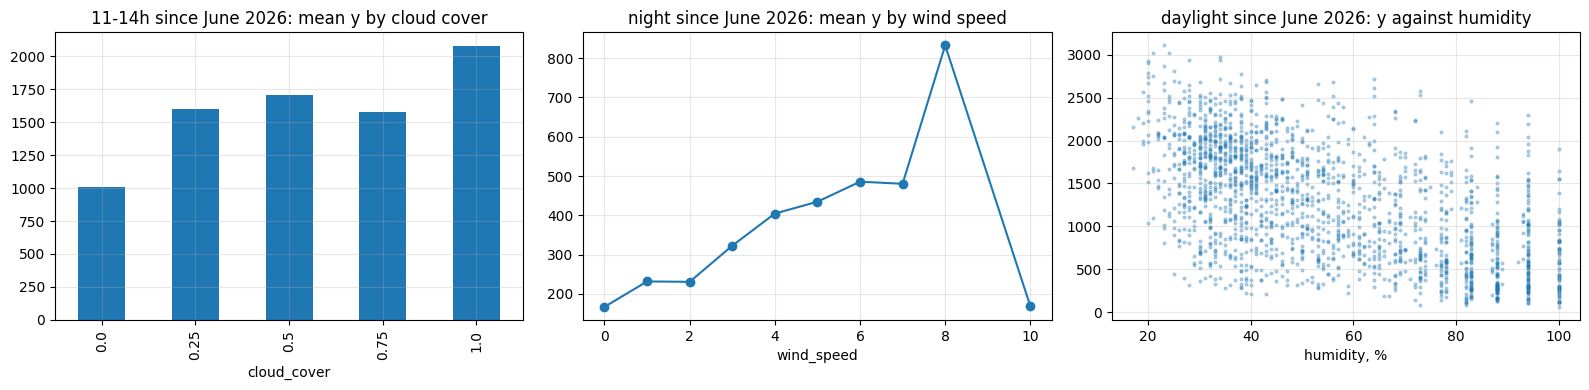

cloud-cover counts at 11-14h since June 2026: {0.0: 15, 0.25: 112, 0.5: 52, 0.75: 1, 1.0: 412}


,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
last 7 days (actual),0.29,10.80,2.01,763.29,91.83,0.38,1.25
next 48 h (forecast),0.61,9.04,2.56,760.50,95.83,0.38,1.26
October 2026,0.56,12.46,2.89,759.98,84.55,0.41,1.24


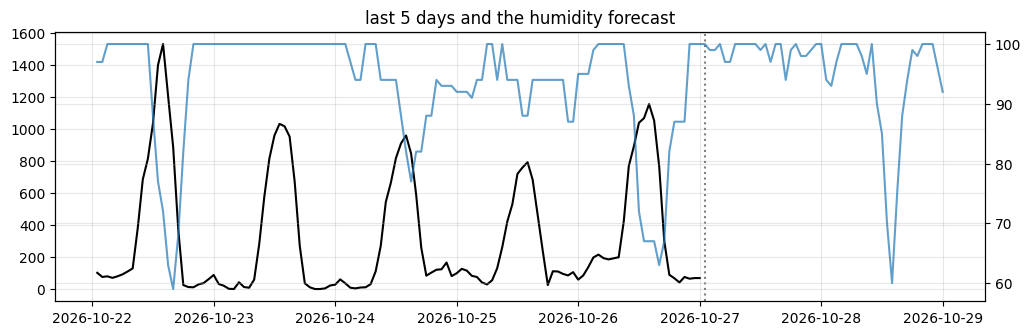

In [9]:
WEATHER = ["cloud_cover", "temperature", "wind_speed", "pressure", "humidity", "daylight", "air_density"]
recent_df = data[dates >= "2026-06-01"]
day_hours = recent_df[recent_df["daylight"] == 1]
corr = pd.DataFrame({"all hours, whole history": data[["y"] + WEATHER].corr()["y"].drop("y"),
                     "daylight hours, since June 2026": day_hours[["y"] + WEATHER].corr()["y"].drop("y")}).T
display(corr.round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
noon = recent_df[recent_df["ds"].dt.hour.isin([11, 12, 13, 14])]
noon.groupby("cloud_cover")["y"].mean().plot(kind="bar", ax=axes[0], title="11-14h since June 2026: mean y by cloud cover")
recent_df[recent_df["daylight"] == 0].groupby("wind_speed")["y"].mean().plot(ax=axes[1], marker="o", title="night since June 2026: mean y by wind speed")
axes[2].scatter(day_hours["humidity"], day_hours["y"], s=4, alpha=0.3)
axes[2].set_title("daylight since June 2026: y against humidity")
axes[2].set_xlabel("humidity, %")
plt.tight_layout()
plt.show()
print("cloud-cover counts at 11-14h since June 2026:", noon["cloud_cover"].value_counts().sort_index().to_dict())

compare = pd.DataFrame({"last 7 days (actual)": data.iloc[-7 * DAY:][WEATHER].mean(),
                        "next 48 h (forecast)": weather_fc[WEATHER].mean(),
                        "October 2026": data[(dates >= "2026-10-01")][WEATHER].mean()}).T
display(compare.round(2))

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(dates.iloc[-5 * DAY:], y[-5 * DAY:], color="black", label="y")
ax2 = ax.twinx()
both = pd.concat([data[["ds", "humidity"]], weather_fc[["ds", "humidity"]]], ignore_index=True).iloc[len(y) - 5 * DAY:]
ax2.plot(both["ds"], both["humidity"],
         color="tab:blue", alpha=0.7, label="humidity (then forecast)")
ax.axvline(FUTURE.iloc[0], color="grey", ls=":")
ax.set_title("last 5 days and the humidity forecast")
plt.show()

**What the EDA shows** *(numbers from the cells above)*

1. **The portfolio grows fast — level shifts, not a stable level.** Mean generation by year: 171 (2023), 184 (2024),
   292 (2025), **684 (2026)**; the monthly mean went from ~300 in January 2026 to ~890 in August–September 2026.
   Part of it is the season (summer is high), most of it is new capacity. *Consequence:* only the recent history
   describes today's level: classical models are fitted on a few weeks (2.5–2.6 test 1 to 26 weeks), and the
   boosting model gets lagged levels so that it does not learn 2023's level.
2. **The daily cycle dominates.** Periodogram: the 24-hour period carries ~44% of the power (plus its 12-hour
   harmonic); MSTL on the last 12 weeks: $F_S(24) = 0.91$ on the original scale. Generation peaks at 11–14 h
   (sun) and has a night floor (~170 on average, wind).
3. **There is no weekly cycle.** Day-of-week means are flat (299–326), $F_S(168) = 0.11$ on the original scale and
   0 on the log scale, and 168 hours carries <1% of the power. *Consequence:* one season, m = 24; the weekly
   Fourier terms of the first notebook only added noise (that is why ARIMA got worse with them).
4. **Multi-day weather cycles.** The next strongest periods are ~100–120 hours: weather systems of 4–5 days.
   A univariate model cannot anticipate them; this is the argument for the weather regressors.
5. **Multiplicative season.** The daily swing grows with the daily level: corr = 0.92 over the whole history,
   0.77 over the last 12 weeks. On the log scale it turns to −0.70 (over-corrected); Box-Cox with Guerrero's
   λ ≈ 0.45 brings it to ≈ 0 (Section 2.2). Both scales are tried: Box-Cox stabilises the variance best, log
   suits MAPE.
6. **Weather drivers.** At night generation rises with wind speed (since June 2026: ~170 at 0 m/s → ~490 at
   6 m/s) — a wind component. In daylight **humidity** is the strongest driver (corr ≈ −0.57 since June 2026);
   cloud cover behaves against intuition (the cloudiest noon hours are the most productive, and 70% of them are
   coded 1.0), so the models get all weather columns and learn the relation themselves.
7. **The 48 hours ahead.** The forecast is very humid (~96% on average) and cloudier than the last week, with
   little wind — a dull, low-generation period is likely. The last week already declined day by day, and in
   2025 November was 27% below October: the horizon sits at the start of the seasonal fall. The seasonal naive
   copies the last day (26 October) and cannot see any of this.

### 2.2 Transformation: log or Box-Cox?

In [10]:
recent = y[-12 * 7 * DAY:]
days = dates.iloc[-12 * 7 * DAY:].dt.normalize().to_numpy()
lam_g = float(boxcox_lambda(recent, method="guerrero", season_length=24))
print(f"Guerrero lambda, last 12 weeks: {lam_g:.3f};  whole history: {float(boxcox_lambda(y, method='guerrero', season_length=24)):.3f}")
rows = {}
for lam in (1, 0.45, 0.25, 0):
    v = np.log(recent) if lam == 0 else boxcox(recent, lam)
    g = pd.DataFrame({"v": v, "d": days}).groupby("d")["v"]
    rows[f"lambda = {lam}" + (" (log)" if lam == 0 else " (none)" if lam == 1 else "")] = g.mean().corr(g.max() - g.min())
display(pd.Series(rows, name="corr(daily level, daily swing), last 12 weeks").round(2).to_frame().T)
print(f"LAMBDA used for 'bc' models: {LAMBDA}")

Guerrero lambda, last 12 weeks: 0.453;  whole history: 0.038


,lambda = 1 (none),lambda = 0.45,lambda = 0.25,lambda = 0 (log)
"corr(daily level, daily swing), last 12 weeks",0.77,-0.0,-0.4,-0.7


LAMBDA used for 'bc' models: 0.45


→ Guerrero's λ on the recent history is ≈ 0.45 (on the whole history ≈ 0, because the growth dominates).
λ = 0.45 removes the level–swing link (corr ≈ 0); the log over-corrects (corr ≈ −0.7). Each model family is fitted
on both scales — `"bc"` (Box-Cox 0.45) and `"log"` — and the windows decide. The log has one argument of its own:
an error on the log scale is a percentage, and the score includes MAPE.

### 2.3 One protocol for every model

A forecaster is `f(end, h)`: it forecasts hours `end … end+h-1` from `y[:end]` and the weather of those hours
(actual inside the history, `weather_fc` for the submission). `run(family, {...})` scores it on the same 20
windows; `window_table` gives the mean RMSE / MAPE / Winkler / coverage on the judged hours (day 2 by default),
**skill = score / seasonal naive's** (below 1 wins), `won` (windows with the lowest RMSE) and `beat bench` (windows
where it beat the seasonal naive). The sun-position features (`day_length`, `sun_position`, `clear_sky`, day of year)
are built from the `daylight` column in `weather_features` and reach every weather model.

In [11]:
NAN = lambda h: np.full(h, np.nan)
FORECASTERS, MIXES, POST, FAMILY, FINAL = {}, {}, {}, {}, {}
bt = None
BASE_COLS = ("window", "step", "actual", "daylight", "benchmark", "benchmark lo", "benchmark hi")
PURGE = -(-H // STEP) - 1          # neighbours this close share hours with a window (1 for 48-hour windows a day apart)


def fwd(x, kind):
    x = np.asarray(x, float)
    if kind == "log":
        return np.log(x)
    if kind == "bc":
        return boxcox(x, LAMBDA)
    return x


def inv(z, kind):
    z = np.asarray(z, float)
    if kind == "log":
        return np.exp(z)
    if kind == "bc":
        return np.power(np.maximum(LAMBDA * z + 1, 1e-12), 1 / LAMBDA)
    return z


def weather_features(df: pd.DataFrame) -> pd.DataFrame:
    # the weather as regressors, plus the physical interactions trees and linear models cannot find alone
    df = df.reset_index(drop=True)
    out = df[["daylight", "cloud_cover", "temperature", "wind_speed", "humidity", "pressure", "air_density"]].astype(float).copy()
    out["sun"] = out["daylight"] * (1 - out["cloud_cover"])         # clear sky while the sun is up
    out["humid_day"] = out["daylight"] * out["humidity"]             # humidity matters while the sun is up
    out["wind3"] = out["wind_speed"] ** 3 / 100                      # wind power grows with the cube of the speed
    # Where the sun is, from the daylight column alone (no outside data): how long the day is, how far into its
    # daylight hours an hour lies, a clear-sky curve peaking at solar noon, and the season. 0/1 daylight cannot say
    # that late-October days are shorter and the sun lower, which is what the models missed in window 1.
    ds = pd.to_datetime(df["ds"])
    day = ds.dt.normalize().to_numpy()
    light = out["daylight"].to_numpy()
    length = pd.Series(light).groupby(day).transform("sum").to_numpy()
    order = pd.Series(light).groupby(day).cumsum().to_numpy()
    position = np.where(light == 1, (order - 0.5) / np.maximum(length, 1), 0.0)
    out["day_length"] = length
    out["sun_position"] = position
    out["clear_sky"] = np.where(light == 1, np.sin(np.pi * position), 0.0)
    out["doy_sin"] = np.sin(2 * np.pi * ds.dt.dayofyear.to_numpy() / 365.25)
    out["doy_cos"] = np.cos(2 * np.pi * ds.dt.dayofyear.to_numpy() / 365.25)
    return out


FEAT_DF = weather_features(pd.concat([data.drop(columns="y"), weather_fc], ignore_index=True))   # history, then the forecast
FEAT_COLS = list(FEAT_DF.columns)
FEAT = FEAT_DF.to_numpy()
ALL_DATES = pd.concat([dates, FUTURE], ignore_index=True)
COV_COLS = ["humidity", "wind_speed", "cloud_cover", "temperature", "daylight", "humid_day", "wind3"]   # the weather
SUN_COLS = ["day_length", "sun_position", "clear_sky", "doy_sin", "doy_cos"]                           # the sun


def cov(cols, start, stop):
    # covariate rows (len(cols), stop - start) for the absolute hours start .. stop-1 (the forecast after the history)
    return FEAT_DF[cols].to_numpy(float)[start:stop].T


def _clean(out, h) -> dict:
    get = lambda *keys: next((np.asarray(out[k], float).ravel()[:h] for k in keys if k in out), NAN(h))
    return {"mean": get("mean"), "lo": get("lo", "lo-95"), "hi": get("hi", "hi-95")}


def on_scale(fit_predict, transform="log"):
    # fit_predict(x, end, h) sees fwd(y[:end]); its forecasts come back on the original scale
    def forecast(end, h):
        out = _clean(fit_predict(fwd(y[:end], transform), end, h), h)
        out = {k: inv(v, transform) for k, v in out.items()}
        out["mean"], out["lo"] = np.maximum(out["mean"], 0), np.maximum(out["lo"], 0)
        return out
    return forecast


def sf(make, transform="log", context=1344, level=True):
    # a statsforecast model: make() builds a fresh one, fitted on the last `context` hours
    def fit_predict(x, end, h):
        x = x[-context:] if context else x
        return make().forecast(y=x, h=h, level=[95]) if level else make().forecast(y=x, h=h)
    return on_scale(fit_predict, transform)


FORECASTERS["benchmark"] = lambda end, h: dict(zip(("mean", "lo", "hi"), snaive(y[:end], h)))


def window_ends(windows=None):
    # where each window ends: window 1 ends with the history, the others STEP hours apart before it
    return [len(y) - (k - 1) * STEP for k in range(windows or WINDOWS, 0, -1)]


def backtest(forecasters: dict, windows=None) -> pd.DataFrame:
    # every forecaster on every window, each window forecast from the hours before it only
    windows = windows or WINDOWS
    ends = window_ends(windows)
    frames = []
    for k, e in zip(range(windows, 0, -1), ends):
        p, lo, hi = snaive(y[:e - H])
        frames.append(pd.DataFrame({"window": k, "step": np.arange(1, H + 1), "actual": y[e - H:e],
                                    "daylight": data["daylight"].to_numpy()[e - H:e],
                                    "benchmark": p, "benchmark lo": lo, "benchmark hi": hi}))
    frame = pd.concat(frames, ignore_index=True)
    bench_rmse = np.mean([rmse(g["actual"], g["benchmark"]) for _, g in frame.groupby("window")])
    seconds = {}
    for name, f in forecasters.items():
        start = time.time()
        try:
            parts = [_clean(f(e - H, H), H) for e in ends]
            if any(np.isnan(p["mean"]).any() for p in parts):
                raise ValueError("NaN in the forecast")
        except Exception as err:
            print(f"  ✗ {name}: {type(err).__name__}: {str(err)[:200]}")
            continue
        FORECASTERS[name] = f
        for key, col in (("mean", name), ("lo", f"{name} lo"), ("hi", f"{name} hi")):
            frame[col] = np.concatenate([p[key] for p in parts])
        seconds[name] = time.time() - start
        r = np.mean([rmse(g["actual"], g[name]) for _, g in frame.groupby("window")])
        print(f"  ✓ {name:<46s} RMSE {r:8.1f}  (skill {r / bench_rmse:.3f})   {seconds[name]:.1f}s", flush=True)
    frame.attrs["seconds"] = seconds
    return frame


def add(bt, new):
    out = bt.drop(columns=[c for c in new.columns if c in bt.columns and c not in BASE_COLS])
    out = pd.concat([out, new[[c for c in new.columns if c not in out.columns]]], axis=1)
    out.attrs["seconds"] = {**bt.attrs.get("seconds", {}), **new.attrs.get("seconds", {})}
    return out


def forecasts_in(bt) -> list[str]:
    return [c for c in bt.columns if c not in BASE_COLS and not c.endswith((" lo", " hi"))] + ["benchmark"]


def _part(frame, part=None):
    # the rows of the judged hours: day 2 = steps 25-48 (the private part), day 1 = steps 1-24, all = 1-48
    part = part or PART
    if part == "day2":
        return frame[frame["step"] > DAY]
    if part == "day1":
        return frame[frame["step"] <= DAY]
    return frame


def _per_window(rows, f, lo=None, hi=None):
    # RMSE, MAPE (and Winkler, coverage) of forecast f in each window of `rows`, as arrays (fast: no groupby)
    _, ix = np.unique(rows["window"].to_numpy(), return_inverse=True)
    n = np.bincount(ix)
    a, f = rows["actual"].to_numpy(float), np.asarray(f, float)
    out = [np.sqrt(np.bincount(ix, (a - f) ** 2) / n), np.bincount(ix, np.abs((a - f) / a)) / n * 100]
    if lo is not None:
        lo, hi = np.asarray(lo, float), np.asarray(hi, float)
        miss = np.clip(lo - a, 0, None) + np.clip(a - hi, 0, None)
        out += [np.bincount(ix, (hi - lo) + 40 * miss) / n, np.bincount(ix, ((a >= lo) & (a <= hi)).astype(float)) / n]
    return out


def window_table(columns=None, per_window=False, part=None) -> pd.DataFrame:
    # mean over the windows of the template's scores on the judged hours; skill = score / benchmark's;
    # won = windows with the lowest RMSE; beat bench = windows with a lower RMSE than the seasonal naive
    columns = list(dict.fromkeys((forecasts_in(bt) if columns is None else list(columns)) + ["benchmark"]))
    rows = _part(bt, part)
    ids = np.unique(rows["window"].to_numpy())
    stats_, per = {}, {}
    for c in columns:
        has = rows[f"{c} lo"].notna().all()
        r, m, *wc = _per_window(rows, rows[c], rows[f"{c} lo"] if has else None, rows[f"{c} hi"] if has else None)
        stats_[c] = {"RMSE": r.mean(), "MAPE": m.mean(), "Winkler": wc[0].mean() if has else np.nan,
                     "coverage": wc[1].mean() if has else np.nan}
        per[c] = pd.Series(r, index=ids)
    tab = pd.DataFrame(stats_).T
    b = tab.loc["benchmark"]
    tab["RMSE skill"], tab["MAPE skill"] = tab["RMSE"] / b["RMSE"], tab["MAPE"] / b["MAPE"]
    tab["point skill"] = (tab["RMSE skill"] + tab["MAPE skill"]) / 2
    tab["Winkler skill"] = tab["Winkler"] / b["Winkler"]
    w_rmse = pd.DataFrame(per)
    tab["won"] = [int((w_rmse.idxmin(axis=1) == c).sum()) for c in tab.index]
    tab["beat bench"] = [int((w_rmse[c] < w_rmse["benchmark"]).sum()) for c in tab.index]
    tab["seconds"] = [bt.attrs.get("seconds", {}).get(c, np.nan) for c in tab.index]
    tab = tab.sort_values("point skill")
    if per_window:
        return tab, (w_rmse.T / w_rmse["benchmark"]).loc[tab.index].round(2)
    return tab


def run(family: str, forecasters: dict, rerun=False) -> pd.DataFrame:
    global bt
    todo = {n: f for n, f in forecasters.items() if rerun or bt is None or n not in bt.columns}
    if todo:
        print(f"{family}: {len(todo)} forecaster(s) x {WINDOWS} windows")
        new = backtest(todo)
        bt = new if bt is None else add(bt, new)
    for n in forecasters:
        if n in bt.columns:
            FAMILY[n] = family
            if n in todo:
                FINAL.pop(n, None)            # re-run: its 48-hour forecast is computed again at the export
    return window_table([n for n in forecasters if n in bt.columns])


def best_of(family: str) -> str:
    names = [n for n, f in FAMILY.items() if f == family and n in bt.columns]
    return window_table(names).drop(index="benchmark")["point skill"].idxmin()


def combine(names, label, how="mean", interval_from=None):
    # the members' mean (or median); the interval: the members' mean interval, or -- interval_from -- that member's
    # own interval stretched to contain the combined point (for members without an interval of their own)
    names = [n for n in dict.fromkeys(names) if n in bt.columns]
    MIXES[label], FAMILY[label] = (names, how, interval_from), "combination"
    FINAL.pop(label, None)
    agg = (lambda cols, **kw: bt[cols].median(axis=1, **kw)) if how == "median" else (lambda cols, **kw: bt[cols].mean(axis=1, **kw))
    bt[label] = agg(names)
    if interval_from:
        bt[f"{label} lo"] = np.minimum(bt[f"{interval_from} lo"], bt[label])
        bt[f"{label} hi"] = np.maximum(bt[f"{interval_from} hi"], bt[label])
    else:
        bt[f"{label} lo"] = agg([f"{n} lo" for n in names], skipna=False)
        bt[f"{label} hi"] = agg([f"{n} hi" for n in names], skipna=False)


def others(w):
    # the windows that share no hour with window w: w and its PURGE neighbours on each side are left out
    return bt[(bt["window"] - w).abs() > PURGE]


def _radius(actual, point, daylight, recipe):
    # the 95% conformal radius from past errors: additive, or additive split day / night
    err = np.abs(np.asarray(actual, float) - np.asarray(point, float))
    if recipe == "conformal day/night":
        return {d: np.quantile(err[np.asarray(daylight) == d], 0.95) for d in (0, 1)}
    return np.quantile(err, 0.95)


def _bounds(point, daylight, r, recipe):
    point = np.asarray(point, float)
    rr = np.where(np.asarray(daylight) == 1, r[1], r[0]) if recipe == "conformal day/night" else r
    return np.maximum(point - rr, 0), point + rr


SCALES = np.round(np.arange(0.5, 1.501, 0.05), 2)


def _scaled(point, lo, hi, c):
    # the interval stretched (c > 1) or shrunk (c < 1) around the point forecast
    point, lo, hi = (np.asarray(v, float) for v in (point, lo, hi))
    return np.maximum(point - c * (point - lo), 0), point + c * (hi - point)


def _best_scale(rows, label):
    # the width factor with the lowest mean Winkler on `rows`
    p, lo, hi = rows[label], rows[f"{label} lo"], rows[f"{label} hi"]
    return min(SCALES, key=lambda c: _per_window(rows, p, *_scaled(p, lo, hi, c))[2].mean())


RECIPES = ["conformal", "conformal day/night"]
POOL_K = 3
POOL_RECIPE = f"median of {POOL_K} best intervals"


def _edges(light):
    # the hours around sunrise and sunset, where an hour's error in timing costs most: the first 4 lit hours of a day,
    # the last lit hour and the 2 dark hours after it (from the daylight flags, so they move with the clock change)
    light = np.asarray(light).astype(int)
    out, run = np.zeros(len(light), bool), 0
    for i, lit in enumerate(light):
        run = run + 1 if lit else 0
        out[i] |= bool(lit) and run <= 4
        if lit and (i + 1 == len(light) or not light[i + 1]):
            out[i:i + 3] = True
    return out


def _pool_bounds(lo, hi, own_lo, own_hi, light):
    # the median bounds; around sunrise and sunset the model's own bounds where they are wider: the hidden days start
    # with a clock change (the daylight flags move one hour on 27 October) that no backtest window contains, and the
    # own interval of the pair is wide enough there for both timings
    if own_lo is None:
        return lo, hi
    e = _edges(light)
    return np.where(e, np.minimum(lo, own_lo), lo), np.where(e, np.maximum(hi, own_hi), hi)


def _interval_pool(label, part=None):
    # every single model with an interval of its own, scored window by window by the Winkler of that interval
    # stretched to contain label's point: (sources, window ids, sources x windows)
    rows = _part(bt, part)
    srcs = [c for c in forecasts_in(bt) if c not in ("benchmark", label)
            and FAMILY.get(c) not in ("simple", "combination", "post-processed")
            and f"{c} lo" in rows.columns and rows[f"{c} lo"].notna().all() and rows[f"{c} hi"].notna().all()]
    p, a = rows[label].to_numpy(float)[:, None], rows["actual"].to_numpy(float)[:, None]
    lo = np.minimum(np.maximum(rows[[f"{c} lo" for c in srcs]].to_numpy(float), 0), p)
    hi = np.maximum(rows[[f"{c} hi" for c in srcs]].to_numpy(float), p)
    wk = (hi - lo) + 40 * (np.clip(lo - a, 0, None) + np.clip(a - hi, 0, None))                   # rows x sources
    win = rows["window"].to_numpy()
    ids = np.unique(win)
    return srcs, ids, np.stack([wk[win == w].mean(axis=0) for w in ids], axis=1)                 # sources x windows


def _pool_top(pool, windows):
    # the POOL_K sources with the lowest mean Winkler on `windows`
    srcs, ids, per = pool
    return [srcs[i] for i in np.argsort(per[:, np.isin(ids, list(windows))].mean(axis=1))[:POOL_K]]


def interval_check(label: str, part=None) -> pd.DataFrame:
    # every recipe judged on windows it did not see: radius / width factor / the best intervals from the windows
    # sharing no hour with it
    rows = []
    pool = _interval_pool(label, part)
    for w in sorted(bt["window"].unique()):
        g, o = _part(bt[bt["window"] == w], part), _part(others(w), part)
        recipes = {rec: _bounds(g[label], g["daylight"], _radius(o["actual"], o[label], o["daylight"], rec), rec) for rec in RECIPES}
        if g[f"{label} lo"].notna().all():
            recipes["own interval"] = (g[f"{label} lo"].to_numpy(), g[f"{label} hi"].to_numpy())
            recipes["own interval x c"] = _scaled(g[label], g[f"{label} lo"], g[f"{label} hi"], _best_scale(o, label))
        if pool[0]:
            top = _pool_top(pool, [v for v in pool[1] if abs(v - w) > PURGE])
            p = g[label].to_numpy(float)
            own = g[f"{label} lo"].notna().all()
            lo, hi = _pool_bounds(np.median([g[f"{c} lo"] for c in top], axis=0), np.median([g[f"{c} hi"] for c in top], axis=0),
                                  g[f"{label} lo"].to_numpy(float) if own else None, g[f"{label} hi"].to_numpy(float) if own else None,
                                  g["daylight"].to_numpy())
            recipes[POOL_RECIPE] = (np.minimum(np.maximum(lo, 0), p), np.maximum(hi, p))
        for rec, (lo, hi) in recipes.items():
            s = score(g["actual"], g[label], lo, hi)
            rows.append({"recipe": rec, "window": w, "Winkler": s["Winkler"], "coverage": s["coverage"],
                         "width": float(np.mean(np.asarray(hi) - np.asarray(lo)))})
    return pd.DataFrame(rows).groupby("recipe")[["Winkler", "coverage", "width"]].mean().sort_values("Winkler")


SHADE_FACTORS = np.round(np.arange(0.1, 1.001, 0.05), 2)
SHADE_LEVELS = (50, 100, 150, 200, 300)


def _shade(point, a, level):
    # the night rule: forecasts below `level` multiplied by a (MAPE punishes over-forecasting small values hardest)
    point = np.asarray(point, float)
    return np.where(point < level, a * point, point)


def _tune_post(frame, base, factors=SHADE_FACTORS):
    # the night rule (a, level) with the lowest RMSE skill + MAPE skill on the judged hours of `frame`
    # (base: a Series on frame's index); returns a, level and the RMSE skill + MAPE skill reached
    rows = _part(frame)
    b = base[rows.index].to_numpy()
    br, bm = _per_window(rows, rows["benchmark"])
    obj = lambda a, level: sum(v.mean() / ref.mean() for v, ref in zip(_per_window(rows, _shade(b, a, level)), (br, bm)))
    a, level = min(((a, L) for a in factors for L in SHADE_LEVELS), key=lambda p: obj(*p))
    return float(a), int(level), float(obj(a, level))


def postprocess(day_label, night_label=None, name=None, shade=True) -> str:
    # 1) the day model in daylight hours; at night the same model or its log-scale version, whichever scores
    #    better (night_label fixes it);
    # 2) the night rule: forecasts below `level` multiplied by a (shade=False: no rule).
    # The interval: the one of the model used at each hour, stretched to include the point; its width is judged in
    # interval_check like any model's. The night model, a and level are tuned on the windows sharing no hour with
    # the scored one (purged leave-one-window-out), so bt holds an honest score; the submission uses them tuned on
    # all windows.
    log = f"{day_label} log"
    nights = [night_label] if night_label else [day_label] + ([log] if log in bt.columns else [])
    name = name or f"{day_label} [{'post' if shade else 'hybrid'}]"
    factors = SHADE_FACTORS if shade else (1.0,)
    night = bt["daylight"].to_numpy() == 0
    pick = lambda n, s: pd.Series(np.where(night, bt[n + s], bt[day_label + s]), index=bt.index)

    def tune(frame):
        # [night model, a, level]: the night model whose tuned rule reaches the lowest RMSE skill + MAPE skill
        fits = {n: _tune_post(frame, pick(n, "")[frame.index], factors) for n in nights}
        n = min(fits, key=lambda k: fits[k][2])
        return [n, *fits[n][:2]]

    point, plo, phi = (pd.Series(np.nan, index=bt.index) for _ in range(3))
    chosen = []
    for w in sorted(bt["window"].unique()):
        n, a, level = tune(others(w))
        chosen.append(("log" if n == log else "same" if n == day_label else n, a, level))
        idx = bt.index[bt["window"] == w]
        point[idx] = _shade(pick(n, "")[idx], a, level)
        plo[idx] = np.minimum(pick(n, " lo")[idx], point[idx])
        phi[idx] = np.maximum(pick(n, " hi")[idx], point[idx])
    bt[name], bt[f"{name} lo"], bt[f"{name} hi"] = point, plo, phi
    n, a, level = tune(bt)
    POST[name], FAMILY[name] = {"day": day_label, "night": n, "a": a, "level": level}, "post-processed"
    FINAL.pop(name, None)
    print(f"{name}: night = {n}; submission rule a = {a}, level = {level}; held-out windows chose (night, a, level) "
          f"{pd.Series([str(x) for x in chosen]).value_counts().to_dict()}")
    return name


def from_all_of_y(label: str) -> dict:
    # every forecaster inside `label` once more on the WHOLE history (cached), averaged / post-processed as in bt
    if label not in FINAL:
        if label in MIXES:
            names, how, interval_from = MIXES[label]
            parts = {n: from_all_of_y(n) for n in names}
            agg = np.median if how == "median" else np.mean
            point = agg([p["mean"] for p in parts.values()], axis=0)
            if interval_from:
                lo, hi = np.minimum(parts[interval_from]["lo"], point), np.maximum(parts[interval_from]["hi"], point)
            else:
                lo, hi = (agg([p[k] for p in parts.values()], axis=0) for k in ("lo", "hi"))
            FINAL[label] = {"mean": point, "lo": lo, "hi": hi}
        elif label in POST:
            p = POST[label]
            d_, n_ = from_all_of_y(p["day"]), from_all_of_y(p["night"])
            night = weather_fc["daylight"].to_numpy()[:H] == 0
            base, lo, hi = (np.where(night, n_[k], d_[k]) for k in ("mean", "lo", "hi"))
            point = _shade(base, p["a"], p["level"])
            FINAL[label] = {"mean": point, "lo": np.minimum(lo, point), "hi": np.maximum(hi, point)}
        else:
            FINAL[label] = _clean(FORECASTERS[label](len(y), H), H)
    return FINAL[label]


def final_forecast(label: str, interval: str):
    # the 48 hours from the whole history; a conformal radius or width factor is fitted for each day of the horizon
    # separately (on all windows' day-1 errors for hours 1-24, on their day-2 errors for hours 25-48)
    fc = from_all_of_y(label)
    point = np.maximum(fc["mean"], 0)
    lo, hi = np.array(fc["lo"], float), np.array(fc["hi"], float)
    light = weather_fc["daylight"].to_numpy()[:H]
    for part, sl in (("day1", slice(0, DAY)), ("day2", slice(DAY, H))):
        rows = _part(bt, part)
        if interval == "own interval x c":
            lo[sl], hi[sl] = _scaled(point[sl], fc["lo"][sl], fc["hi"][sl], _best_scale(rows, label))
        elif interval in RECIPES:
            r = _radius(rows["actual"], rows[label], rows["daylight"], interval)
            lo[sl], hi[sl] = _bounds(point[sl], light[sl], r, interval)
        elif interval == POOL_RECIPE:
            pool = _interval_pool(label, part)
            top = _pool_top(pool, pool[1])                    # ranked on all windows' errors of this day
            own = not np.isnan(fc["lo"][sl]).any()
            lo[sl], hi[sl] = _pool_bounds(np.median([from_all_of_y(c)["lo"][sl] for c in top], axis=0),
                                          np.median([from_all_of_y(c)["hi"][sl] for c in top], axis=0),
                                          fc["lo"][sl] if own else None, fc["hi"][sl] if own else None, light[sl])
            print(f"{part}: the interval is the median of the bounds of {top}" + (", own bounds kept around sunrise and sunset" if own else ""))
        elif interval != "own interval":
            raise ValueError("interval: 'own interval', 'own interval x c', POOL_RECIPE or one of RECIPES")
    if np.isnan(lo).any():
        raise ValueError(f"{label} has no interval of its own: use a conformal recipe")
    return point, np.minimum(np.maximum(lo, 0), point), np.maximum(hi, point)


def plot_validation(names, window=1, show=72):
    g = bt[bt["window"] == window]
    end = len(y) - (window - 1) * STEP
    x = dates.iloc[end - H:end]
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(dates.iloc[end - H - show:end - H], y[end - H - show:end - H], color="grey", lw=0.8, label="history")
    ax.plot(x, g["actual"], color="black", lw=1.6, label="actual")
    ax.plot(x, g["benchmark"], color="grey", ls="--", lw=1.2, label="seasonal naive")
    ax.axvline(x.iloc[DAY - 1], color="grey", ls=":", lw=1)
    for n in names:
        ax.plot(x, g[n], lw=1.4, label=f"{n} (RMSE {rmse(g['actual'], g[n]):.1f})")
        if len(names) == 1 and g[f"{n} lo"].notna().all():
            ax.fill_between(x, g[f"{n} lo"], g[f"{n} hi"], alpha=0.2, label="95% interval")
    ax.set_title(f"window {window}" + (" (the template's validation window)" if window == 1 else "") + ": day 1 | day 2")
    ax.legend(loc="upper left", fontsize=8)
    plt.show()


RESULTS_DIR = "results"   # the exported model tables (<prefix>_bt.csv, <prefix>_final.csv) live here


def export(prefix: str):
    # the rolling-window table and each model's 48-hour forecast from the whole history, for merging elsewhere
    names = [n for n in forecasts_in(bt) if n != "benchmark" and n not in MIXES and n not in POST]
    Path(RESULTS_DIR).mkdir(exist_ok=True)
    bt[list(BASE_COLS) + [c for n in names for c in (n, f"{n} lo", f"{n} hi")]].to_csv(f"{RESULTS_DIR}/{prefix}_bt.csv", index=False)
    rows = []
    for n in names:
        try:
            fc = from_all_of_y(n)
        except Exception as err:
            print(f"  ✗ final forecast of {n}: {type(err).__name__}: {str(err)[:120]}")
            continue
        rows += [{"model": n, "family": FAMILY.get(n, "?"), "step": i + 1, "mean": fc["mean"][i], "lo": fc["lo"][i],
                  "hi": fc["hi"][i]} for i in range(H)]
    pd.DataFrame(rows).to_csv(f"{RESULTS_DIR}/{prefix}_final.csv", index=False)
    print(f"saved {RESULTS_DIR}/{prefix}_bt.csv ({len(names)} models) and {RESULTS_DIR}/{prefix}_final.csv")


def merge(prefix: str):
    # adds another notebook's exported models to bt, FAMILY and FINAL (the same windows are checked)
    global bt
    other = pd.read_csv(f"{RESULTS_DIR}/{prefix}_bt.csv")
    assert len(other) == len(bt) and (other["window"].to_numpy() == bt["window"].to_numpy()).all() \
        and np.allclose(other["actual"], bt["actual"]), "not the same windows: WINDOWS and STEP must match"
    new = [c for c in other.columns if c not in BASE_COLS]
    seconds = bt.attrs.get("seconds", {})
    bt = pd.concat([bt.drop(columns=[c for c in new if c in bt.columns]), other[new]], axis=1)
    bt.attrs["seconds"] = seconds
    fin = pd.read_csv(f"{RESULTS_DIR}/{prefix}_final.csv")
    for n, g in fin.groupby("model"):
        g = g.sort_values("step")
        FINAL[n] = {k: g[k].to_numpy(float) for k in ("mean", "lo", "hi")}
        FAMILY[n] = g["family"].iloc[0]
    print(f"merged {fin['model'].nunique()} models from {prefix}")

### 2.4 Simple methods

In [12]:
def simple(kind):
    def forecast(end, h):
        hist = y[:end]
        if kind.startswith("mean of last"):
            n = int(kind.split()[3])
            return {"mean": np.array([hist[-DAY * n:].reshape(n, DAY)[:, i % DAY].mean() for i in range(h)])}
        if kind.startswith("median of last"):
            n = int(kind.split()[3])
            return {"mean": np.array([np.median(hist[-DAY * n:].reshape(n, DAY)[:, i % DAY]) for i in range(h)])}
    return forecast


display(run("simple", {k: simple(k) for k in ["mean of last 2 days", "mean of last 3 days", "median of last 7 days"]}))
elapsed()

simple: 3 forecaster(s) x 20 windows
  ✓ mean of last 2 days                            RMSE    307.7  (skill 0.984)   0.0s


  ✓ mean of last 3 days                            RMSE    316.2  (skill 1.011)   0.0s


  ✓ median of last 7 days                          RMSE    349.7  (skill 1.118)   0.0s


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
mean of last 3 days,328.009,610.419,NaN,NaN,0.977,0.535,0.756,NaN,4,10,0.002
median of last 7 days,355.308,570.598,NaN,NaN,1.058,0.500,0.779,NaN,7,9,0.008
mean of last 2 days,324.233,820.714,NaN,NaN,0.966,0.719,0.842,NaN,3,13,0.002
benchmark,335.736,1141.315,2740.292,0.817,1.000,1.000,1.000,1.0,6,0,NaN


[0.1 min since the start of Section 2]


### 2.5 ETS on different amounts of training data (Lab 5)

**By hand first.** Season `A` on a transformed scale (`M` on the original: the swing grows with the level, 2.1 #5);
trend `N` or `Ad` — over a few weeks the level moves (growth, then the autumn fall) but should not be extrapolated
for two days, so damped; error `A` on the transformed scale. The hand pick is **ETS(A,Ad,A) on Box-Cox, 4 weeks**.

Then every specification on every training length: 1, 2, 4, 8, 12 and 26 weeks before each window. A short window
follows the current level; a long one estimates the daily profile from more days but mixes in older levels.

ETS: 42 forecaster(s) x 20 windows


  ✓ ETS(A,Ad,A) bc, 1w                             RMSE    314.9  (skill 1.007)   0.2s


  ✓ ETS(A,Ad,A) bc, 2w                             RMSE    287.0  (skill 0.918)   0.4s


  ✓ ETS(A,Ad,A) bc, 4w                             RMSE    271.1  (skill 0.867)   0.9s


  ✓ ETS(A,Ad,A) bc, 8w                             RMSE    277.4  (skill 0.887)   1.8s


  ✓ ETS(A,Ad,A) bc, 12w                            RMSE    289.3  (skill 0.925)   2.7s


... (41 outputs left out)

Winkler skill:


training,1w,2w,4w,8w,12w,26w
model,,,,,,
AutoETS bc,3.600,2.701,1.420,1.401,0.977,0.962
"ETS(A,Ad,A) bc",0.733,0.577,0.683,0.789,0.846,0.934
"ETS(A,Ad,A) log",1.538,1.033,0.958,1.004,0.993,1.127
"ETS(A,N,A) bc",0.680,0.543,0.780,0.846,0.891,0.962
"ETS(A,N,A) log",1.279,0.990,1.263,1.426,1.777,1.899
"ETS(M,Ad,M)",1.449,1.007,1.201,1.234,1.117,1.151
"ETS(M,N,M)",1.416,0.958,1.115,1.277,1.165,1.348


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
"ETS(A,Ad,A) log, 2w",317.546,542.494,2832.020,0.844,0.946,0.475,0.711,1.033,2,13,0.438
"ETS(A,Ad,A) bc, 4w",283.398,735.895,1871.316,0.829,0.844,0.645,0.744,0.683,2,14,0.910
"ETS(A,Ad,A) bc, 2w",297.562,692.883,1581.234,0.858,0.886,0.607,0.747,0.577,0,14,0.441
"ETS(A,Ad,A) bc, 8w",289.823,740.319,2162.200,0.777,0.863,0.649,0.756,0.789,0,14,1.797
"ETS(A,Ad,A) log, 4w",335.869,587.101,2624.320,0.792,1.000,0.514,0.757,0.958,1,12,0.892
"ETS(A,Ad,A) log, 1w",368.972,475.212,4213.899,0.821,1.099,0.416,0.758,1.538,0,10,0.230
"ETS(A,N,A) bc, 4w",301.783,722.626,2136.845,0.819,0.899,0.633,0.766,0.780,0,12,0.601
"ETS(A,N,A) bc, 2w",284.865,783.567,1489.194,0.863,0.848,0.687,0.768,0.543,0,15,0.302


best ETS: ETS(A,Ad,A) log, 2w


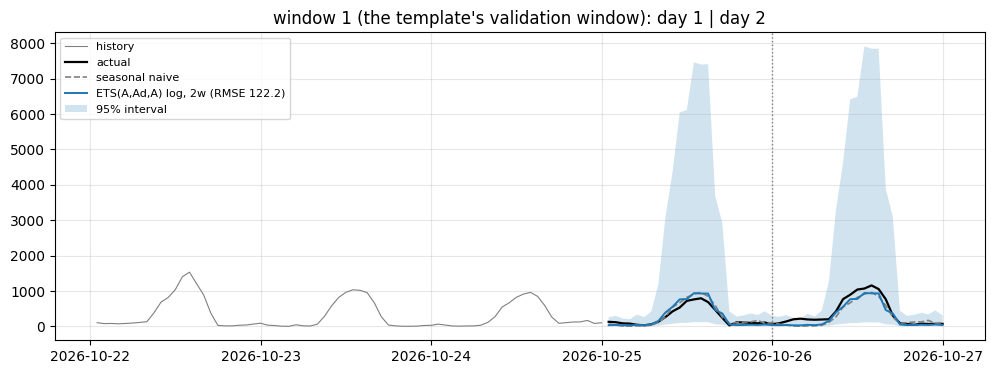

[2.4 min since the start of Section 2]


In [13]:
CONTEXTS = {"1w": 168, "2w": 336, "4w": 672, "8w": 1344, "12w": 2016, "26w": 4368}   # <-- training lengths (hours)
ETS_SPECS = {                       # <-- name: (letters, scale); letters None = AutoETS
    "ETS(A,Ad,A) bc":  ("AAdA", "bc"),
    "ETS(A,N,A) bc":   ("ANA", "bc"),
    "ETS(A,Ad,A) log": ("AAdA", "log"),
    "ETS(A,N,A) log":  ("ANA", "log"),
    "ETS(M,Ad,M)":     ("MAdM", None),
    "ETS(M,N,M)":      ("MNM", None),
    "AutoETS bc":      (None, "bc"),
}


def _ets_model(spec=None, m=DAY):
    if spec is None:
        return AutoETS(season_length=m)
    spec, damped = str(spec).strip().upper(), False
    if len(spec) == 4 and spec[2] == "D":
        spec, damped = spec[:2] + spec[3], True
    return AutoETS(season_length=m, model=spec, damped=damped if spec[1] != "N" else None)


ets_forecasters = {f"{name}, {c}": sf(lambda spec=spec: _ets_model(spec), transform=kind, context=n)
                   for name, (spec, kind) in ETS_SPECS.items() for c, n in CONTEXTS.items()}
ets_table = run("ETS", ets_forecasters)


def grid_view(table, value="point skill"):
    t = table.drop(index="benchmark").copy()
    t["model"] = [n.rsplit(", ", 1)[0] for n in t.index]
    t["training"] = [n.rsplit(", ", 1)[1] for n in t.index]
    order = [c for c in CONTEXTS if c in set(t["training"])]
    return t.pivot(index="model", columns="training", values=value)[order]


print("point skill (mean of RMSE and MAPE skill; below 1 beats the seasonal naive) by training length:")
display(grid_view(ets_table).round(3))
print("RMSE skill:")
display(grid_view(ets_table, "RMSE skill").round(3))
print("Winkler skill:")
display(grid_view(ets_table, "Winkler skill").round(3))
ETS_BEST = best_of("ETS")
display(ets_table.head(8))
print("best ETS:", ETS_BEST)
plot_validation([ETS_BEST])
elapsed()

→

### 2.6 ARIMA (Labs 6–7): the reading, a grid, training lengths, the weather

log scale, last 8 weeks, m = 24: D = 1, d = 0;  95% band = ±0.054


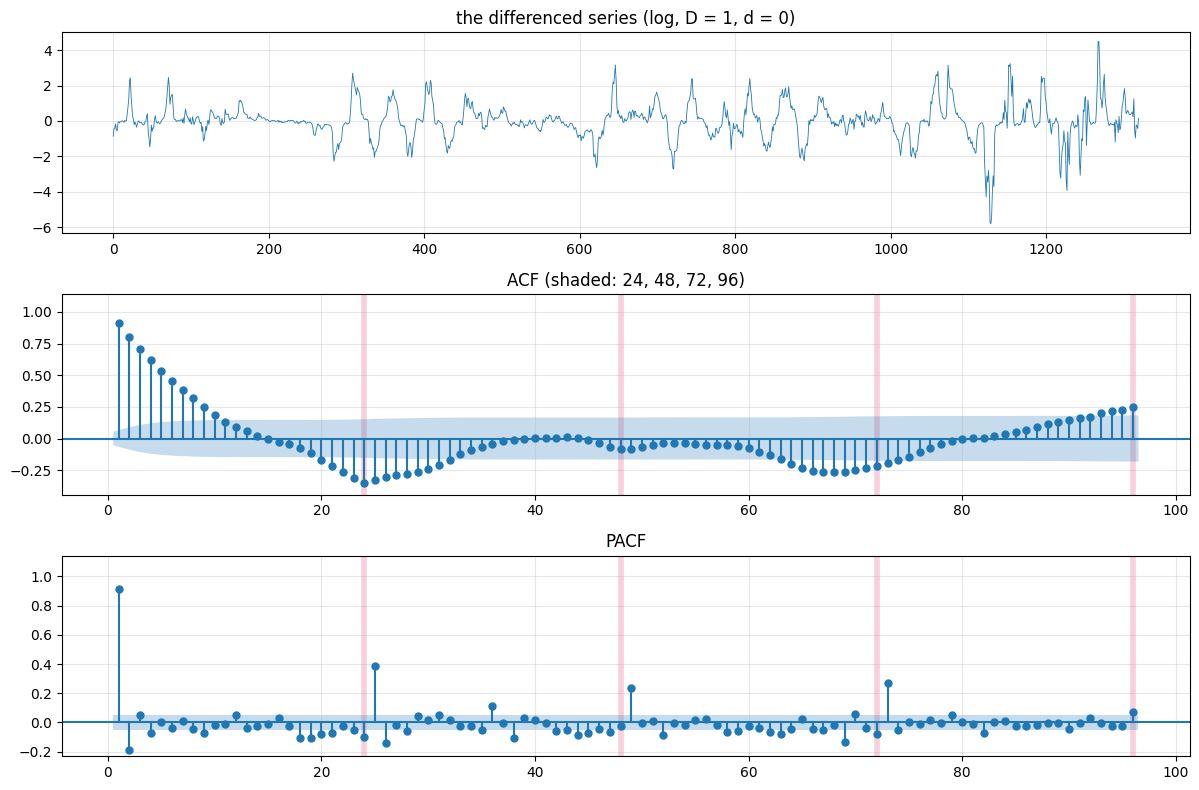

ACF  at 1..4: [0.91 0.8  0.71 0.62]  at 24, 48, 72, 96: [-0.35 -0.08 -0.22  0.25]
PACF at 1..4: [ 0.91 -0.19  0.05 -0.07]  at 25, 49, 73, 97: [0.38 0.24 0.27 0.11]


In [14]:
ARIMA_M = DAY
x8 = np.log(y[-1344:])
D = int(nsdiffs(x8, period=ARIMA_M))
z = x8[ARIMA_M:] - x8[:-ARIMA_M] if D else x8.copy()
d = int(ndiffs(z))
z = np.diff(z, n=d) if d else z
print(f"log scale, last 8 weeks, m = {ARIMA_M}: D = {D}, d = {d};  95% band = ±{1.96 / np.sqrt(len(z)):.3f}")

fig, axes = plt.subplots(3, 1, figsize=(12, 8))
axes[0].plot(z, lw=0.6)
axes[0].set_title(f"the differenced series (log, D = {D}, d = {d})")
plot_acf(z, lags=4 * DAY, zero=False, ax=axes[1], auto_ylims=True, title="ACF (shaded: 24, 48, 72, 96)")
plot_pacf(z, lags=4 * DAY, zero=False, ax=axes[2], auto_ylims=True, title="PACF")
for ax in axes[1:]:
    for k in range(DAY, 4 * DAY + 1, DAY):
        ax.axvline(k, color="#e64173", alpha=0.25, lw=4, zorder=0)
plt.tight_layout()
plt.show()
from statsmodels.tsa.stattools import acf, pacf
a, p = acf(z, nlags=4 * DAY + 1, fft=True), pacf(z, nlags=4 * DAY + 1, method="ywm")
print("ACF  at 1..4:", np.round(a[1:5], 2), " at 24, 48, 72, 96:", np.round(a[[24, 48, 72, 96]], 2))
print("PACF at 1..4:", np.round(p[1:5], 2), " at 25, 49, 73, 97:", np.round(p[[25, 49, 73, 97]], 2))

**Reading the ACF and PACF** (log, D = 1, d = 0, last 8 weeks)

- **Non-seasonal part.** The ACF decays geometrically (0.91, 0.80, 0.71, …) and the PACF cuts off after lag 2
  (0.91, −0.19, then ≈ 0): an **AR(2)**, p = 2, q = 0 (AR(1) is the close alternative).
- **Seasonal part.** After the seasonal difference the ACF has one negative spike at lag 24 (≈ −0.35) and is near 0
  at 48; the PACF around the seasonal lags *decays* (≈ 0.38 at 25, 0.24 at 49, ≈ 0.07 at 97). A spike cutting off in
  the ACF with a decaying PACF is a **seasonal MA(1)**: Q = 1, P = 0.
- Lags 24, 72, 96 are **seasonal** lags — they name P and Q, not p and q (an AR(96) would take minutes per fit).
- **Hand pick: SARIMA(2,0,0)(0,1,1)[24]** on log. The alternative reading (P = 2–3, Q = 2–3 from the bumps at 72 and
  96) is in the grid below and decided by AICc and the windows.

In [15]:
AUTO_ARIMA_KW = {"approximation": True}
ARIMA_X = ["humidity", "wind_speed", "cloud_cover", "temperature", "daylight", "humid_day", "wind3"]   # <-- regressors


def fourier(t, m, K):
    t = np.asarray(t, float)
    return np.column_stack([f(2 * np.pi * k * t / m) for k in range(1, K + 1) for f in (np.sin, np.cos)])


def regressors(t, K=None, weather=False):
    blocks = [fourier(t, m, k) for m, k in (K or {}).items() if k]
    if weather:
        blocks.append(FEAT_DF[ARIMA_X].to_numpy(float)[np.asarray(t, int)])
    return np.column_stack(blocks) if blocks else None


def _arima_fit(x, t0, order=None, seasonal=(0, 0, 0), fourier_K=None, weather=False, seasonal_search=True):
    X = regressors(np.arange(t0, t0 + len(x)), fourier_K, weather)
    if order is None:
        model = AutoARIMA(season_length=ARIMA_M, seasonal=seasonal_search, **AUTO_ARIMA_KW)
    else:
        model = ARIMA(order=tuple(order), seasonal_order=tuple(seasonal), season_length=ARIMA_M)
    return model.fit(y=x, X=X)


def arima(transform="log", context=1344, **spec):
    def fit_predict(x, end, h):
        t0 = max(0, end - context)
        model = _arima_fit(x[t0:], t0, **spec)
        return model.predict(h=h, X=regressors(np.arange(end, end + h), spec.get("fourier_K"), spec.get("weather")), level=[95])
    return on_scale(fit_predict, transform)


def arima_info(transform="log", context=1344, **spec) -> dict:
    # fitted once on the last `context` hours of `past`; AICc comparable only with the same d, D, scale and data
    x = fwd(past, transform)
    t0 = len(x) - context
    start = time.time()
    fit = _arima_fit(x[t0:], t0, **spec)
    p_, q_, P_, Q_ = fit.model_["arma"][:4]
    resid = pd.Series(fit.model_["residuals"])
    return {"fitted on past": str(ARIMASummary(fit.model_)).strip(), "AICc": fit.model_["aicc"],
            "LB p (48)": acorr_ljungbox(resid, lags=[48], model_df=p_ + q_ + P_ + Q_)["lb_pvalue"].iloc[0],
            "resid acf(24)": resid.autocorr(24), "fit s": time.time() - start}


# Stage 1: the grid -- p from lags 1-3, q 0/1, and seasonal (P, Q) from the reading and the alternative reading.
P_GRID, Q_GRID = [1, 2, 3], [0, 1]
SEASONAL_GRID = [(0, 1), (1, 1), (0, 2), (1, 0), (2, 2), (2, 3), (3, 2), (3, 3)]
GRID = {f"({p_},{d},{q_})({P_},{D},{Q_})": {"order": (p_, d, q_), "seasonal": (P_, D, Q_)}
        for p_ in P_GRID for q_ in Q_GRID for P_, Q_ in SEASONAL_GRID}
screen = {}
for name, spec in GRID.items():
    try:
        screen[name] = arima_info(**spec)
    except Exception as err:
        screen[name] = {"fitted on past": f"failed: {type(err).__name__}"}
screen = pd.DataFrame(screen).T.sort_values("AICc")
print(f"{len(GRID)} candidates on the log scale, last 8 weeks of `past` (NaN AICc = the likelihood did not converge):")
display(screen)
elapsed()

48 candidates on the log scale, last 8 weeks of `past` (NaN AICc = the likelihood did not converge):


,fitted on past,AICc,LB p (48),resid acf(24),fit s
"(1,0,1)(3,1,2)","ARIMA(1,0,1)(3,1,2)[24]",590.639,0.0,0.006,5.134
"(1,0,1)(3,1,3)","ARIMA(1,0,1)(3,1,3)[24]",593.548,0.0,0.007,6.342
"(1,0,1)(2,1,3)","ARIMA(1,0,1)(2,1,3)[24]",606.218,0.0,-0.041,5.609
"(3,0,0)(2,1,3)","ARIMA(3,0,0)(2,1,3)[24]",611.057,0.0,-0.038,2.47
"(2,0,0)(2,1,3)","ARIMA(2,0,0)(2,1,3)[24]",615.428,0.0,-0.038,5.371
"(1,0,1)(0,1,1)","ARIMA(1,0,1)(0,1,1)[24]",617.751,0.0,0.021,0.733
"(1,0,1)(2,1,2)","ARIMA(1,0,1)(2,1,2)[24]",617.961,0.0,-0.026,2.244
"(3,0,1)(0,1,1)","ARIMA(3,0,1)(0,1,1)[24]",618.717,0.0,0.023,0.764
"(2,0,1)(0,1,1)","ARIMA(2,0,1)(0,1,1)[24]",618.986,0.0,0.022,0.596
"(1,0,1)(0,1,2)","ARIMA(1,0,1)(0,1,2)[24]",619.601,0.0,-0.005,1.668


[3.6 min since the start of Section 2]


In [16]:
# Stage 2: the hand pick, the alternative reading, and the best of the grid by AICc -- on several training lengths.
ARIMA_CONTEXTS = {"4w": 672, "8w": 1344} if QUICK else {"2w": 336, "4w": 672, "8w": 1344}   # <-- training lengths
HAND_ARIMA = [f"(2,{d},0)(0,{D},1)", f"(1,{d},0)(0,{D},1)", f"(2,{d},1)(0,{D},1)", f"(2,{d},0)(2,{D},2)"]   # <-- the reading + the alternative
by_aicc = [n for n in screen.index if pd.notna(screen.loc[n, "AICc"])]
SELECTED = list(dict.fromkeys(HAND_ARIMA[:1] + by_aicc[:1] if QUICK else HAND_ARIMA + by_aicc[:2]))
print("backtested:", SELECTED)
arima_forecasters = {f"SARIMA{n} log, {c}": arima(context=ctx, **GRID[n]) for n in SELECTED for c, ctx in ARIMA_CONTEXTS.items()}
arima_forecasters["AutoARIMA log, 4w"] = arima(context=672, order=None)
arima_table = run("ARIMA", arima_forecasters)
print("point skill by training length:")
display(grid_view(arima_table).round(3))
display(arima_table.head(8))
elapsed()

backtested: ['(2,0,0)(0,1,1)', '(1,0,1)(3,1,2)']
ARIMA: 5 forecaster(s) x 20 windows


  ✓ SARIMA(2,0,0)(0,1,1) log, 4w                   RMSE    338.8  (skill 1.083)   5.0s


  ✓ SARIMA(2,0,0)(0,1,1) log, 8w                   RMSE    320.5  (skill 1.025)   10.0s


  ✓ SARIMA(1,0,1)(3,1,2) log, 4w                   RMSE    376.1  (skill 1.203)   76.1s


  ✓ SARIMA(1,0,1)(3,1,2) log, 8w                   RMSE    352.8  (skill 1.128)   103.7s


  ✓ AutoARIMA log, 4w                              RMSE    376.4  (skill 1.203)   51.5s


point skill by training length:


training,4w,8w
model,,
AutoARIMA log,0.743,NaN
"SARIMA(1,0,1)(3,1,2) log",0.655,0.679
"SARIMA(2,0,0)(0,1,1) log",0.656,0.666


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
"SARIMA(1,0,1)(3,1,2) log, 4w",333.736,361.083,2838.729,0.875,0.994,0.316,0.655,1.036,2,10,76.085
"SARIMA(2,0,0)(0,1,1) log, 4w",311.350,438.959,3301.467,0.860,0.927,0.385,0.656,1.205,4,12,5.015
"SARIMA(2,0,0)(0,1,1) log, 8w",315.775,447.029,2704.359,0.846,0.941,0.392,0.666,0.987,4,11,10.037
"SARIMA(1,0,1)(3,1,2) log, 8w",326.279,440.816,2804.561,0.846,0.972,0.386,0.679,1.023,0,12,103.699
"AutoARIMA log, 4w",352.100,498.566,3257.103,0.854,1.049,0.437,0.743,1.189,3,9,51.536
benchmark,335.736,1141.315,2740.292,0.817,1.000,1.000,1.000,1.000,7,0,NaN


[7.7 min since the start of Section 2]


ARIMA: 2 forecaster(s) x 20 windows


  ✓ SARIMA(1,0,1)(3,1,2) + weather log, 4w         RMSE    343.4  (skill 1.098)   134.1s


  ✓ DHR K=5 + weather log, 4w                      RMSE    301.7  (skill 0.965)   23.9s


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
"SARIMA(1,0,1)(3,1,2) + weather log, 4w",300.943,356.994,2722.695,0.885,0.896,0.313,0.605,0.994,7,12,134.143
"DHR K=5 + weather log, 4w",274.417,555.103,2872.974,0.840,0.817,0.486,0.652,1.048,6,13,23.862
benchmark,335.736,1141.315,2740.292,0.817,1.000,1.000,1.000,1.000,7,0,NaN


best ARIMA-family model: SARIMA(1,0,1)(3,1,2) + weather log, 4w


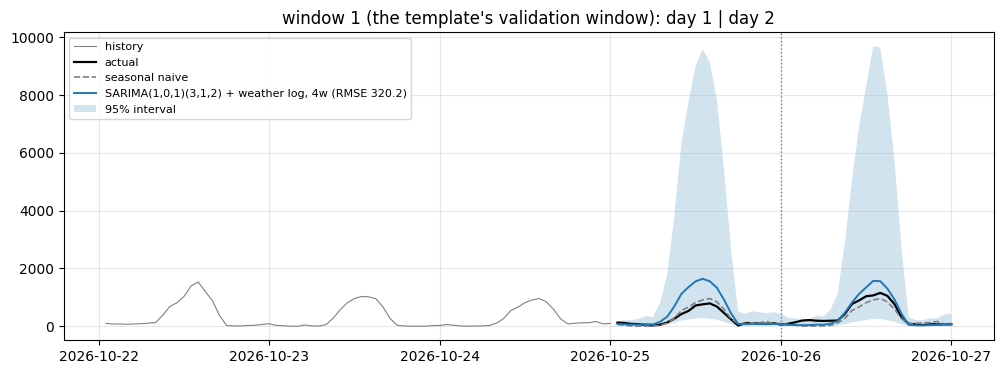

[10.4 min since the start of Section 2]


In [17]:
# Stage 3: the weather as regressors (regression with SARIMA errors, ARIMAX) for the two best (order, length),
# on log and Box-Cox; and dynamic harmonic regression with the daily season only (no weekly season, 2.1 #3).
plain = window_table([n for n in arima_table.index if n.startswith("SARIMA")]).drop(index="benchmark")
weather_forecasters = {}
for n in plain.index[:1 if QUICK else 2]:                    # QUICK: the best one on log (the rest: family_ARIMA)
    order_name, ctx_name = n.removeprefix("SARIMA").split(" log, ")
    for kind in (("log",) if QUICK else ("log", "bc")):
        weather_forecasters[f"SARIMA{order_name} + weather {kind}, {ctx_name}"] = arima(
            transform=kind, context=ARIMA_CONTEXTS[ctx_name], weather=True, **GRID[order_name])
for K in ((5,) if QUICK else (5, 10)):
    for c in (("4w",) if QUICK else ("4w", "8w")):
        weather_forecasters[f"DHR K={K} + weather log, {c}"] = arima(context=ARIMA_CONTEXTS[c], order=None, seasonal_search=False,
                                                                    fourier_K={DAY: K}, weather=True)
display(run("ARIMA", weather_forecasters))
ARIMA_BEST = best_of("ARIMA")
print("best ARIMA-family model:", ARIMA_BEST)
plot_validation([ARIMA_BEST])
elapsed()

→

### 2.7 Prophet (lecture: *Advanced methods*)

Piecewise-linear trend + daily Fourier season (no weekly season, 2.1 #3), with and without the weather as extra
regressors, on the log scale; its own 95% interval. Trained on the last 60, 120 or 365 days.

In [18]:
from prophet import Prophet

PROPHET_X = ["humidity", "wind_speed", "cloud_cover", "temperature", "daylight", "humid_day", "wind3"]


def prophet_model(days=120, weather=True, transform="log"):
    def fit_predict(x, end, h):
        start = max(0, end - DAY * days)
        df = pd.DataFrame({"ds": dates.iloc[start:end].to_numpy(), "y": x[start:]})
        fut = pd.DataFrame({"ds": ALL_DATES.iloc[end:end + h].to_numpy()})
        model = Prophet(daily_seasonality=10, weekly_seasonality=False, yearly_seasonality=days >= 730,
                        interval_width=0.95, changepoint_prior_scale=0.05, uncertainty_samples=300)
        if weather:
            for c in PROPHET_X:
                model.add_regressor(c)
                df[c] = FEAT_DF[c].to_numpy()[start:end]
                fut[c] = FEAT_DF[c].to_numpy()[end:end + h]
        model.fit(df)
        fc = model.predict(fut)
        return {"mean": fc["yhat"].to_numpy(), "lo": fc["yhat_lower"].to_numpy(), "hi": fc["yhat_upper"].to_numpy()}
    return on_scale(fit_predict, transform)


PROPHETS = {
    "Prophet log, 120d":             prophet_model(120, weather=False),
    "Prophet + weather log, 120d":   prophet_model(120),
}
if not QUICK:
    PROPHETS.update({"Prophet + weather log, 60d": prophet_model(60), "Prophet + weather log, 365d": prophet_model(365)})
display(run("Prophet", PROPHETS))
elapsed()

Prophet: 2 forecaster(s) x 20 windows


18:33:21 - cmdstanpy - INFO - Chain [1] start processing


18:33:21 - cmdstanpy - INFO - Chain [1] done processing


18:33:21 - cmdstanpy - INFO - Chain [1] start processing


18:33:21 - cmdstanpy - INFO - Chain [1] done processing


18:33:21 - cmdstanpy - INFO - Chain [1] start processing


... (75 outputs left out)

18:33:31 - cmdstanpy - INFO - Chain [1] done processing


  ✓ Prophet + weather log, 120d                    RMSE    277.4  (skill 0.887)   5.5s


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
"Prophet + weather log, 120d",267.359,342.367,1879.201,0.806,0.796,0.300,0.548,0.686,9,15,5.535
"Prophet log, 120d",287.341,414.625,2134.449,0.792,0.856,0.363,0.610,0.779,7,12,5.015
benchmark,335.736,1141.315,2740.292,0.817,1.000,1.000,1.000,1.000,4,0,NaN


[10.5 min since the start of Section 2]


→

### 2.8 Gradient boosting on the weather (LightGBM)

The strongest model of the exam session, improved:

- **two stages:** the first day of the horizon can use the lags 24–47 hours back (yesterday at the same hour is
  known for hours 1–24); the second day only lags ≥ 48. Two models, one per day;
- **relative target:** the model learns log y minus the mean of the last 7 days (known at the forecast origin), so a
  level it has never seen (the 2026 growth) does not confuse the trees;
- training length 90, 180, 365, 730 days; log vs Box-Cox; with / without the weather;
- **quantile models** (2.5% and 97.5%) for an interval of its own.

In [19]:
import lightgbm as lgb

LGB_PARAMS = dict(n_estimators=600, learning_rate=0.03, num_leaves=63, min_child_samples=20, subsample=0.8,
                  subsample_freq=1, colsample_bytree=0.8, verbose=-1)


def lgb_design(x, rows, min_lag, weather=True, relative=False):
    # features of the hours in `rows`, using only values at least `min_lag` hours old
    xs = pd.Series(np.r_[x, np.full(H, np.nan)])
    dd = ALL_DATES.iloc[rows]
    level = xs.shift(min_lag).rolling(7 * DAY).mean().to_numpy()[rows]
    cols = {"hour": dd.dt.hour.to_numpy(), "doy_sin": np.sin(2 * np.pi * dd.dt.dayofyear.to_numpy() / 365.25),
            "doy_cos": np.cos(2 * np.pi * dd.dt.dayofyear.to_numpy() / 365.25)}
    for k in [min_lag + DAY * i for i in range(6)]:
        cols[f"lag{k}"] = xs.shift(k).to_numpy()[rows] - (level if relative else 0)
    cols["mean_last_day"] = xs.shift(min_lag).rolling(DAY).mean().to_numpy()[rows] - (level if relative else 0)
    cols["level_7d"] = level
    if weather:
        cols.update({c: FEAT_DF[c].to_numpy()[rows] for c in FEAT_COLS})
    return pd.DataFrame(cols), level


def lightgbm_model(days=365, transform="log", weather=True, two_stage=True, relative=False, quantiles=False, seed=1):
    def fit_predict(x, end, h):
        rows = np.arange(max(400, end - DAY * days), end)
        stages = [(DAY, 0, DAY), (2 * DAY, DAY, h)] if two_stage else [(2 * DAY, 0, h)]
        out = {"mean": np.full(h, np.nan), "lo": np.full(h, np.nan), "hi": np.full(h, np.nan)}
        for min_lag, a, b in stages:
            X, lev = lgb_design(x, rows, min_lag, weather, relative)
            target = x[rows] - (lev if relative else 0)
            ok = ~np.isnan(target)
            Xf, levf = lgb_design(x, np.arange(end + a, end + b), min_lag, weather, relative)
            kinds = {"mean": {}} | ({"lo": {"objective": "quantile", "alpha": 0.025},
                                     "hi": {"objective": "quantile", "alpha": 0.975}} if quantiles else {})
            for key, extra in kinds.items():
                model = lgb.LGBMRegressor(**LGB_PARAMS, random_state=seed, **extra)
                model.fit(X[ok], target[ok])
                out[key][a:b] = model.predict(Xf) + (levf if relative else 0)
        return out
    return on_scale(fit_predict, transform)


LGBMS = {                                   # the three best of the 10-window study
    "LightGBM 2-stage relative log, 730d":    lightgbm_model(730, relative=True),
    "LightGBM 2-stage relative log, 365d":    lightgbm_model(365, relative=True),
    "LightGBM 2-stage log, 180d":             lightgbm_model(180),
}
if not QUICK:
    LGBMS.update({
        "LightGBM log, 365d (exam version)":      lightgbm_model(365, two_stage=False),
        "LightGBM 2-stage log, 365d":             lightgbm_model(365),
        "LightGBM 2-stage log, 90d":              lightgbm_model(90),
        "LightGBM 2-stage log, 730d":             lightgbm_model(730),
        "LightGBM 2-stage bc, 365d":              lightgbm_model(365, transform="bc"),
        "LightGBM 2-stage no weather log, 365d":  lightgbm_model(365, weather=False),
    })
display(run("LightGBM", LGBMS))
elapsed()

LightGBM: 3 forecaster(s) x 20 windows


  ✓ LightGBM 2-stage relative log, 730d            RMSE    230.6  (skill 0.737)   195.8s


  ✓ LightGBM 2-stage relative log, 365d            RMSE    246.6  (skill 0.788)   181.3s


  ✓ LightGBM 2-stage log, 180d                     RMSE    251.8  (skill 0.805)   189.3s


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
"LightGBM 2-stage relative log, 730d",233.655,266.449,NaN,NaN,0.696,0.233,0.465,NaN,8,15,195.759
"LightGBM 2-stage relative log, 365d",252.678,292.790,NaN,NaN,0.753,0.257,0.505,NaN,4,14,181.267
"LightGBM 2-stage log, 180d",267.323,613.153,NaN,NaN,0.796,0.537,0.667,NaN,5,15,189.267
benchmark,335.736,1141.315,2740.292,0.817,1.000,1.000,1.000,1.0,3,0,NaN


[20.0 min since the start of Section 2]


best LightGBM: LightGBM 2-stage relative log, 730d {'days': 730, 'transform': 'log', 'two_stage': True, 'relative': True, 'weather': True}


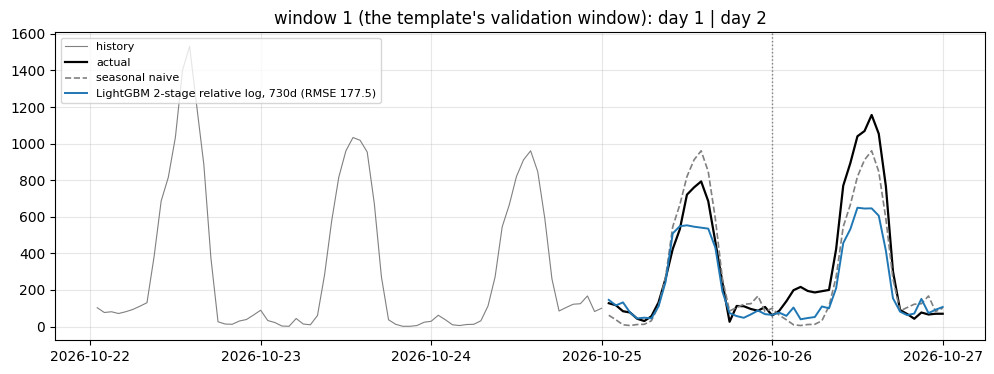

[20.0 min since the start of Section 2]


In [20]:
# The best LightGBM variant once more with quantile models: an interval of its own for the Winkler score.
lgb_names = [n for n, f in FAMILY.items() if f == "LightGBM"]
LGB_BEST = window_table(lgb_names).drop(index="benchmark")["point skill"].idxmin()
settings = {"days": int(LGB_BEST.rsplit(", ", 1)[1].rstrip("d")), "transform": "bc" if " bc," in LGB_BEST else "log",
            "two_stage": "2-stage" in LGB_BEST, "relative": "relative" in LGB_BEST, "weather": "no weather" not in LGB_BEST}
print("best LightGBM:", LGB_BEST, settings)
if not QUICK:                               # quantile models: 3x the time, an interval that under-covered (75%) at 10 windows
    display(run("LightGBM", {f"{LGB_BEST} + quantiles": lightgbm_model(quantiles=True, **settings)}))
plot_validation([LGB_BEST])
elapsed()

→

### 2.9 STL with the daily season only, + ETS or Theta on what is left

In [21]:
display(run("other", {
    f"STL(24) + AutoETS {kind}, {c}": sf(lambda: MSTL(season_length=DAY, trend_forecaster=AutoETS(model="ZZN")),
                                         transform=kind, context=CONTEXTS[c])
    for kind in ("log", "bc") for c in ("2w", "4w", "8w")
} | {
    f"STL(24) + Theta {kind}, 4w": sf(lambda: MSTL(season_length=DAY, trend_forecaster=AutoTheta()), transform=kind, context=672)
    for kind in ("log", "bc")
}))
elapsed()

other: 8 forecaster(s) x 20 windows


  ✓ STL(24) + AutoETS log, 2w                      RMSE    826.4  (skill 2.642)   0.4s


  ✓ STL(24) + AutoETS log, 4w                      RMSE    796.5  (skill 2.547)   0.6s


  ✓ STL(24) + AutoETS log, 8w                      RMSE    819.5  (skill 2.620)   1.1s


  ✓ STL(24) + AutoETS bc, 2w                       RMSE    422.4  (skill 1.351)   0.3s


  ✓ STL(24) + AutoETS bc, 4w                       RMSE    432.6  (skill 1.383)   0.6s


  ✓ STL(24) + AutoETS bc, 8w                       RMSE    428.2  (skill 1.369)   1.1s


  ✓ STL(24) + Theta log, 4w                        RMSE    748.0  (skill 2.392)   0.8s


  ✓ STL(24) + Theta bc, 4w                         RMSE    398.5  (skill 1.274)   0.8s


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
"STL(24) + Theta bc, 4w",419.789,600.815,2018.269,0.919,1.250,0.526,0.888,0.737,3,6,0.818
"STL(24) + AutoETS bc, 8w",449.150,547.103,2434.340,0.994,1.338,0.479,0.909,0.888,2,7,1.138
"STL(24) + AutoETS bc, 4w",453.904,561.389,2768.741,0.998,1.352,0.492,0.922,1.010,1,7,0.583
"STL(24) + AutoETS bc, 2w",444.386,613.611,2649.098,1.000,1.324,0.538,0.931,0.967,0,6,0.308
benchmark,335.736,1141.315,2740.292,0.817,1.000,1.000,1.000,1.000,9,0,NaN
"STL(24) + Theta log, 4w",760.967,621.033,13767.003,0.858,2.267,0.544,1.405,5.024,0,7,0.772
"STL(24) + AutoETS log, 4w",811.711,580.618,20612.065,0.954,2.418,0.509,1.463,7.522,1,5,0.557
"STL(24) + AutoETS log, 8w",834.617,600.821,21851.554,0.915,2.486,0.526,1.506,7.974,2,5,1.104
"STL(24) + AutoETS log, 2w",841.926,606.183,38922.033,0.954,2.508,0.531,1.519,14.204,2,6,0.390


[20.1 min since the start of Section 2]


### 2.10 The other notebooks' models: Colab and the four family notebooks

Every notebook below writes `<name>_bt.csv` and `<name>_final.csv` next to itself; put them next to this notebook and
run the cell: their models join the same table (the windows are checked to be identical).

| Files | Notebook | Models |
|---|---|---|
| `colab_*` | `LUKIANETS_project_colab.ipynb` (Colab, GPU) | foundation models (context × covariate grid), TabPFN, neural networks |
| `family_ets_*` | `family_ETS.ipynb` | ETS on 6 training lengths, Holt-Winters, seasonal ES, CES, the Theta family |
| `family_arima_*` | `family_ARIMA.ipynb` | SARIMA grid and training lengths, AutoARIMA, ARIMAX, DHR |
| `family_decomposition_*` | `family_decomposition.ipynb` | STL / MSTL + 7 trend models, robust STL, classical, MFLES, TBATS |
| `family_ml_*` | `family_ML.ipynb` | Ridge, random forest, extra trees, HistGB, LightGBM, Prophet, analog days |

In [22]:
SOURCES = ["colab", "family_ets", "family_arima", "family_decomposition", "family_ml"]
for prefix in SOURCES:
    if Path(f"{RESULTS_DIR}/{prefix}_bt.csv").exists() and Path(f"{RESULTS_DIR}/{prefix}_final.csv").exists():
        merge(prefix)
    else:
        print(f"not found: {RESULTS_DIR}/{prefix}_bt.csv / {RESULTS_DIR}/{prefix}_final.csv")
print(f"{len([n for n, f in FAMILY.items() if f != 'simple'])} models on the scoreboard")
display(window_table().head(30))

merged 78 models from colab
merged 253 models from family_ets
merged 62 models from family_arima


merged 134 models from family_decomposition


merged 20 models from family_ml
558 models on the scoreboard


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
"Timestral 209M + weather, ctx 32768",206.756,135.137,978.539,0.954,0.616,0.118,0.367,0.357,0,16,NaN
"Timestral 209M + weather, ctx 17520",208.460,137.110,988.640,0.954,0.621,0.120,0.371,0.361,0,17,NaN
"Timestral 209M + weather, ctx 26280",208.880,138.052,987.026,0.952,0.622,0.121,0.372,0.360,0,17,NaN
"Timestral 209M + weather + sun, ctx 32768",207.726,144.346,991.392,0.948,0.619,0.126,0.373,0.362,0,16,NaN
"Timestral 209M + weather + sun, ctx 17520",209.350,144.657,1006.759,0.950,0.624,0.127,0.375,0.367,0,17,NaN
"Timestral 209M + weather + sun, ctx 26280",209.905,144.292,1003.626,0.946,0.625,0.126,0.376,0.366,0,16,NaN
"Timestral 209M + weather, ctx 8760",213.452,149.757,1078.502,0.948,0.636,0.131,0.383,0.394,0,16,NaN
"Timestral 209M + weather + sun, ctx 8760",218.142,157.571,1095.674,0.944,0.650,0.138,0.394,0.400,0,16,NaN
"Timestral 209M + weather, ctx 8760 log",220.212,155.889,1076.452,0.931,0.656,0.137,0.396,0.393,0,16,NaN
"Timestral 123M + weather, ctx 32768",214.478,180.161,964.201,0.958,0.639,0.158,0.398,0.352,0,16,NaN


### 2.11 Combinations

Members by a rule decided in advance, not by trying averages until one wins: the best of each family, and the top 3 /
top 5 **models** by day-2 point skill — one variant per model (Timestral, Chronos-2, TimeGPT, LightGBM, ...), because
variants of the same model make nearly the same errors (correlation 0.9+) and averaging them gains little.

The foundation models also err together (their top 3 are all foundation models), so one more pair of two different
kinds: **the best foundation model** (it reads the history) **+ the best other model** (on these data a weather
regression), with the foundation model's own interval stretched to contain the average (the other member has none).
In the last week of October the level fell sharply: the foundation models over-forecast it while the weather
regressions followed it (2.13 shows the most recent windows apart).

In [23]:
FAMILIES = [f for f in dict.fromkeys(FAMILY.values()) if f not in ("simple", "combination", "post-processed")]
BEST_OF = {f: best_of(f) for f in FAMILIES}
print("best of each family:", BEST_OF)
singles = [n for n, f in FAMILY.items() if f in FAMILIES and n in bt.columns]
ranked = window_table(singles).drop(index="benchmark")["point skill"].sort_values()

def model_of(n):
    # the model behind a variant: "Timestral 209M + weather + sun, ctx 8760" -> "Timestral 209M"; Mac models: their family
    return n.split(" +")[0].split(",")[0] if FAMILY.get(n) in ("foundation", "neural") else FAMILY.get(n)


best_per_model = []
for n in ranked.index:
    if model_of(n) not in {model_of(m) for m in best_per_model}:
        best_per_model.append(n)
print("best variant of each model, by day-2 point skill:", best_per_model[:6])

combine(list(BEST_OF.values()), "best of each family")
combine(best_per_model[:3], "top-3 models average")
combine(best_per_model[:5], "top-5 models average")
combine(best_per_model[:5], "top-5 models median", how="median")
PAIR_FM = next(n for n in best_per_model if FAMILY.get(n) == "foundation")
PAIR_OTHER = next(n for n in best_per_model if FAMILY.get(n) not in ("foundation", "neural"))
combine([PAIR_FM, PAIR_OTHER], "best foundation + best other", interval_from=PAIR_FM)
print(f"best foundation + best other = {PAIR_FM} + {PAIR_OTHER} (interval: {PAIR_FM}'s)")

errors = pd.DataFrame({n: bt["actual"] - bt[n] for n in BEST_OF.values()})
print("correlation of the members' errors over all windows (low = more to gain from averaging):")
display(errors.corr().round(2))
display(window_table(list(BEST_OF.values()) + list(MIXES)))
elapsed()

best of each family: {'ETS': 'ETS(A,N,A) log, 3d', 'ARIMA': 'SARIMA(1,0,1)(3,1,2) + weather log, 4w', 'ARIMAX / DHR': 'DHR K=3 + weather + sun log, 2w', 'Prophet': 'Prophet + weather + sun log, 120d', 'LightGBM': 'LightGBM relative log, 730d', 'other': 'STL(24) + AutoETS bc, 8w', 'decomposition': 'MSTL(24,168) + ARIMA log, 8w', 'foundation': 'Timestral 209M + weather, ctx 32768', 'neural': 'NHITS s1 + weather', 'exp. smoothing (other)': 'CES raw, 4w', 'Theta': 'Theta additive bc, 4w', 'ETS top-down': 'daily ETS(A,Ad,N) x profile bc, 28d', 'ETS per hour': 'per-hour ETS(A,Ad,N) log, 28d', 'ETS + weather': 'weather regression a=30 + ETS(A,N,N) log, 12w', 'ARIMA top-down': 'daily ARIMAX x profile log, 112d', 'decomposition (other)': 'TBATS(24), 4w', 'decomposition + weather': 'STL(24) + ARIMAX log, 2w', 'analog': 'Analog days k=80, 365d', 'trees': 'HistGB relative log, 730d', 'regression': 'Ridge (hour dummies) relative log, 90d'}


best variant of each model, by day-2 point skill: ['Timestral 209M + weather, ctx 32768', 'Timestral 123M + weather, ctx 32768', 'TimesFM 3.0 + weather + sun, ctx 1024', 'Chronos-2 + weather, ctx 672', 'TimeGPT + weather', 'LightGBM relative log, 730d']
best foundation + best other = Timestral 209M + weather, ctx 32768 + LightGBM relative log, 730d (interval: Timestral 209M + weather, ctx 32768's)
correlation of the members' errors over all windows (low = more to gain from averaging):


,"ETS(A,N,A) log, 3d","SARIMA(1,0,1)(3,1,2) + weather log, 4w","DHR K=3 + weather + sun log, 2w","Prophet + weather + sun log, 120d","LightGBM relative log, 730d","STL(24) + AutoETS bc, 8w","MSTL(24,168) + ARIMA log, 8w","Timestral 209M + weather, ctx 32768",NHITS s1 + weather,"CES raw, 4w","Theta additive bc, 4w","daily ETS(A,Ad,N) x profile bc, 28d","per-hour ETS(A,Ad,N) log, 28d","weather regression a=30 + ETS(A,N,N) log, 12w","daily ARIMAX x profile log, 112d","TBATS(24), 4w","STL(24) + ARIMAX log, 2w","Analog days k=80, 365d","HistGB relative log, 730d","Ridge (hour dummies) relative log, 90d"
"ETS(A,N,A) log, 3d",1.00,0.67,0.55,0.50,0.71,0.61,0.66,0.73,0.47,0.64,0.48,0.84,0.84,0.41,0.81,0.71,0.51,0.39,0.69,0.59
"SARIMA(1,0,1)(3,1,2) + weather log, 4w",0.67,1.00,0.79,0.59,0.53,0.84,0.90,0.72,0.64,0.82,0.78,0.53,0.55,0.50,0.67,0.87,0.82,0.36,0.54,0.68
"DHR K=3 + weather + sun log, 2w",0.55,0.79,1.00,0.75,0.63,0.67,0.71,0.67,0.69,0.62,0.76,0.46,0.36,0.70,0.50,0.73,0.79,0.62,0.65,0.57
"Prophet + weather + sun log, 120d",0.50,0.59,0.75,1.00,0.72,0.43,0.52,0.62,0.69,0.63,0.60,0.58,0.44,0.95,0.60,0.72,0.55,0.80,0.69,0.70
"LightGBM relative log, 730d",0.71,0.53,0.63,0.72,1.00,0.46,0.51,0.69,0.61,0.59,0.49,0.78,0.70,0.63,0.72,0.68,0.46,0.72,0.97,0.50
"STL(24) + AutoETS bc, 8w",0.61,0.84,0.67,0.43,0.46,1.00,0.82,0.61,0.68,0.81,0.91,0.44,0.49,0.35,0.58,0.76,0.79,0.25,0.47,0.53
"MSTL(24,168) + ARIMA log, 8w",0.66,0.90,0.71,0.52,0.51,0.82,1.00,0.62,0.60,0.74,0.75,0.55,0.57,0.44,0.64,0.80,0.75,0.34,0.54,0.57
"Timestral 209M + weather, ctx 32768",0.73,0.72,0.67,0.62,0.69,0.61,0.62,1.00,0.67,0.73,0.54,0.66,0.64,0.55,0.79,0.76,0.60,0.49,0.68,0.72
NHITS s1 + weather,0.47,0.64,0.69,0.69,0.61,0.68,0.60,0.67,1.00,0.74,0.77,0.48,0.39,0.65,0.61,0.75,0.58,0.62,0.59,0.56
"CES raw, 4w",0.64,0.82,0.62,0.63,0.59,0.81,0.74,0.73,0.74,1.00,0.81,0.62,0.61,0.54,0.76,0.91,0.66,0.42,0.56,0.69


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
"Timestral 209M + weather, ctx 32768",206.756,135.137,978.539,0.954,0.616,0.118,0.367,0.357,2,16,NaN
best foundation + best other,195.198,182.117,978.539,0.954,0.581,0.160,0.370,0.357,1,18,NaN
top-3 models average,209.969,163.462,NaN,NaN,0.625,0.143,0.384,NaN,2,17,NaN
top-5 models average,213.763,172.548,NaN,NaN,0.637,0.151,0.394,NaN,2,16,NaN
top-5 models median,212.716,176.363,NaN,NaN,0.634,0.155,0.394,NaN,2,16,NaN
"LightGBM relative log, 730d",227.204,236.128,NaN,NaN,0.677,0.207,0.442,NaN,2,17,NaN
"HistGB relative log, 730d",227.497,278.242,NaN,NaN,0.678,0.244,0.461,NaN,1,16,NaN
best of each family,243.887,374.455,NaN,NaN,0.726,0.328,0.527,NaN,2,17,NaN
"weather regression a=30 + ETS(A,N,N) log, 12w",243.217,378.943,2760.870,0.881,0.724,0.332,0.528,1.008,0,17,NaN
"DHR K=3 + weather + sun log, 2w",266.097,308.735,2362.158,0.881,0.793,0.271,0.532,0.862,1,16,NaN


[20.1 min since the start of Section 2]


### 2.12 Post-processing: the night

A decision made *for the scores*, on top of a model's forecast.

**The night.** MAPE divides by the actual value, and at night the actual is small: on the 10-window study, night hours
carried ~90% of all the percentage error, and hours below 50 alone ~70%, while RMSE lives in daylight. So in daylight
the model's forecast on the original scale; at night the same forecast or its **log-scale** version (when it has one),
whichever scores better; and every forecast below `level` multiplied by `a` (an over-forecast of a small value is an
unbounded percentage, an under-forecast costs at most 100%: the MAPE-optimal forecast sits below the median).

**The interval** is the one of the model used at each hour, stretched to include the point; its width is judged in
2.13 like any model's (own interval, own interval × c, conformal, the median of the best intervals). Scaling it here by a factor tuned on the other
windows made the held-out Winkler worse: the best factor moves with the windows that hold a big miss.

The night model, `a` and `level` are tuned on the windows sharing no hour with the scored one (purged
leave-one-window-out), so the table shows **honest** scores; the submission uses them tuned on all 20 windows.
Candidates: the three best models, their average and the foundation + other pair, with the night rule ([post]); those
with a log-scale version also without the rule ([hybrid]: the night model alone). The rule is a bet that the hidden nights are calm: it lowers MAPE
a lot and costs some RMSE when a night turns out windy — compare the rows.

In [24]:
CANDIDATES = best_per_model[:3] + ["top-3 models average", "best foundation + best other"]   # <-- what gets the night rule
post_names = [postprocess(n) for n in CANDIDATES]                        # night model + night rule + width factor
post_names += [postprocess(n, shade=False) for n in CANDIDATES if f"{n} log" in bt.columns]   # without the rule
print("\nday 2 (the private hours):")
display(window_table(CANDIDATES + post_names))
print("all 48 hours:")
display(window_table(CANDIDATES + post_names, part="all"))
elapsed()

Timestral 209M + weather, ctx 32768 [post]: night = Timestral 209M + weather, ctx 32768; submission rule a = 0.1, level = 150; held-out windows chose (night, a, level) {"('same', 0.1, 100)": 9, "('same', 0.1, 150)": 7, "('same', 0.2, 150)": 2, "('same', 0.15, 150)": 1, "('same', 0.15, 100)": 1}
Timestral 123M + weather, ctx 32768 [post]: night = Timestral 123M + weather, ctx 32768; submission rule a = 0.1, level = 150; held-out windows chose (night, a, level) {"('same', 0.1, 150)": 14, "('same', 0.1, 200)": 3, "('same', 0.15, 150)": 1, "('same', 0.25, 200)": 1, "('same', 0.1, 100)": 1}


TimesFM 3.0 + weather + sun, ctx 1024 [post]: night = TimesFM 3.0 + weather + sun, ctx 1024; submission rule a = 0.1, level = 150; held-out windows chose (night, a, level) {"('same', 0.1, 150)": 15, "('same', 0.1, 200)": 2, "('same', 0.15, 200)": 1, "('same', 0.2, 200)": 1, "('same', 0.25, 200)": 1}
top-3 models average [post]: night = top-3 models average; submission rule a = 0.1, level = 150; held-out windows chose (night, a, level) {"('same', 0.1, 150)": 14, "('same', 0.15, 200)": 3, "('same', 0.2, 200)": 1, "('same', 0.25, 200)": 1, "('same', 0.1, 100)": 1}


best foundation + best other [post]: night = best foundation + best other; submission rule a = 0.1, level = 100; held-out windows chose (night, a, level) {"('same', 0.1, 100)": 17, "('same', 0.2, 200)": 1, "('same', 0.15, 150)": 1, "('same', 0.35, 300)": 1}
Timestral 209M + weather, ctx 32768 [hybrid]: night = Timestral 209M + weather, ctx 32768; submission rule a = 1.0, level = 50; held-out windows chose (night, a, level) {"('same', 1.0, 50)": 20}

day 2 (the private hours):


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
best foundation + best other [post],197.858,69.909,978.539,0.954,0.589,0.061,0.325,0.357,1,18,NaN
"Timestral 209M + weather, ctx 32768 [post]",208.995,69.701,978.539,0.954,0.622,0.061,0.342,0.357,0,16,NaN
top-3 models average [post],212.758,70.060,NaN,NaN,0.634,0.061,0.348,NaN,1,17,NaN
"Timestral 123M + weather, ctx 32768 [post]",217.769,71.627,964.204,0.958,0.649,0.063,0.356,0.352,2,15,NaN
"Timestral 209M + weather, ctx 32768",206.756,135.137,978.539,0.954,0.616,0.118,0.367,0.357,2,16,NaN
"Timestral 209M + weather, ctx 32768 [hybrid]",206.756,135.137,978.539,0.954,0.616,0.118,0.367,0.357,0,16,NaN
best foundation + best other,195.198,182.117,978.539,0.954,0.581,0.160,0.370,0.357,5,18,NaN
top-3 models average,209.969,163.462,NaN,NaN,0.625,0.143,0.384,NaN,1,17,NaN
"TimesFM 3.0 + weather + sun, ctx 1024 [post]",232.892,86.081,NaN,NaN,0.694,0.075,0.385,NaN,1,15,NaN
"Timestral 123M + weather, ctx 32768",214.478,180.161,964.201,0.958,0.639,0.158,0.398,0.352,4,16,NaN


all 48 hours:


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
best foundation + best other [post],196.051,62.313,891.681,0.959,0.627,0.083,0.355,0.326,3,19,NaN
"Timestral 209M + weather, ctx 32768 [post]",200.914,60.123,891.796,0.959,0.642,0.080,0.361,0.326,0,17,NaN
top-3 models average [post],206.290,57.819,NaN,NaN,0.660,0.077,0.368,NaN,0,16,NaN
"Timestral 123M + weather, ctx 32768 [post]",211.366,59.848,909.766,0.956,0.676,0.079,0.378,0.333,1,16,NaN
"Timestral 209M + weather, ctx 32768",198.768,109.315,891.670,0.959,0.636,0.145,0.390,0.326,3,17,NaN
"Timestral 209M + weather, ctx 32768 [hybrid]",198.768,109.315,891.670,0.959,0.636,0.145,0.390,0.326,0,17,NaN
best foundation + best other,192.810,139.294,891.670,0.959,0.616,0.185,0.401,0.326,6,19,NaN
"TimesFM 3.0 + weather + sun, ctx 1024 [post]",222.093,70.321,NaN,NaN,0.710,0.093,0.402,NaN,0,15,NaN
top-3 models average,203.669,122.971,NaN,NaN,0.651,0.163,0.407,NaN,1,16,NaN
"Timestral 123M + weather, ctx 32768",208.014,130.804,909.547,0.956,0.665,0.174,0.419,0.333,3,16,NaN


[20.1 min since the start of Section 2]


→

### 2.13 Scoreboard, choice and interval

The final ranking is $0.3\cdot\text{rank}_{RMSE} + 0.3\cdot\text{rank}_{MAPE} + 0.4\cdot\text{rank}_{Winkler}$ on the
private 24 hours (day 2). Its stand-in here: **0.3 · RMSE skill + 0.3 · MAPE skill + 0.4 · Winkler skill on day 2**,
each candidate with its best interval recipe judged on windows it did not see (own interval, own × c, conformal,
conformal day/night, and **the median of the 3 best intervals**: the three models whose own intervals, stretched to
contain the candidate's point, had the lowest Winkler on the other windows, and the median of their bounds — several
similar intervals averaged bound by bound are steadier than one). Around sunrise and sunset (the first 4 lit hours, the
last lit hour and the 2 hours after it) that recipe keeps the candidate's own bounds where they are wider: the daylight
flags move one hour on 27 October (the clock change), in past years the output moved with them within a few days, so
the timing of the ramps on the hidden days is uncertain — a risk no backtest window contains. The window-by-window table shows whether a model wins in most windows or in one lucky one; the
last two columns of the ranking split the day-2 RMSE skill into the five most recent windows and the other 15 — a
model that wins only on the older windows is a risk for the hidden days right after them.

In [25]:
scoreboard, per_window = window_table(per_window=True)            # day 2
display(scoreboard.head(25))
print("all 48 hours:")
display(window_table(part="all").head(15))
print("day-2 RMSE relative to the seasonal naive, window by window (window 1 = the most recent):")
display(per_window.head(15))

,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
best foundation + best other [post],197.858,69.909,978.539,0.954,0.589,0.061,0.325,0.357,0,18,NaN
"Timestral 209M + weather, ctx 32768 [post]",208.995,69.701,978.539,0.954,0.622,0.061,0.342,0.357,0,16,NaN
top-3 models average [post],212.758,70.060,NaN,NaN,0.634,0.061,0.348,NaN,0,17,NaN
"Timestral 123M + weather, ctx 32768 [post]",217.769,71.627,964.204,0.958,0.649,0.063,0.356,0.352,0,15,NaN
"Timestral 209M + weather, ctx 32768 [hybrid]",206.756,135.137,978.539,0.954,0.616,0.118,0.367,0.357,0,16,NaN
"Timestral 209M + weather, ctx 32768",206.756,135.137,978.539,0.954,0.616,0.118,0.367,0.357,0,16,NaN
best foundation + best other,195.198,182.117,978.539,0.954,0.581,0.160,0.370,0.357,0,18,NaN
"Timestral 209M + weather, ctx 17520",208.460,137.110,988.640,0.954,0.621,0.120,0.371,0.361,0,17,NaN
"Timestral 209M + weather, ctx 26280",208.880,138.052,987.026,0.952,0.622,0.121,0.372,0.360,0,17,NaN
"Timestral 209M + weather + sun, ctx 32768",207.726,144.346,991.392,0.948,0.619,0.126,0.373,0.362,0,16,NaN


all 48 hours:


,RMSE,MAPE,Winkler,coverage,RMSE skill,MAPE skill,point skill,Winkler skill,won,beat bench,seconds
best foundation + best other [post],196.051,62.313,891.681,0.959,0.627,0.083,0.355,0.326,1,19,NaN
"Timestral 209M + weather, ctx 32768 [post]",200.914,60.123,891.796,0.959,0.642,0.080,0.361,0.326,0,17,NaN
top-3 models average [post],206.290,57.819,NaN,NaN,0.660,0.077,0.368,NaN,0,16,NaN
"Timestral 123M + weather, ctx 32768 [post]",211.366,59.848,909.766,0.956,0.676,0.079,0.378,0.333,0,16,NaN
"Timestral 209M + weather, ctx 17520",198.278,109.668,890.717,0.963,0.634,0.146,0.390,0.326,1,17,NaN
"Timestral 209M + weather, ctx 32768",198.768,109.315,891.670,0.959,0.636,0.145,0.390,0.326,0,17,NaN
"Timestral 209M + weather, ctx 32768 [hybrid]",198.768,109.315,891.670,0.959,0.636,0.145,0.390,0.326,0,17,NaN
"Timestral 209M + weather, ctx 26280",200.439,109.402,896.461,0.959,0.641,0.145,0.393,0.328,0,18,NaN
"Timestral 209M + weather + sun, ctx 17520",200.636,113.144,905.933,0.960,0.642,0.150,0.396,0.332,0,17,NaN
"Timestral 209M + weather + sun, ctx 32768",200.621,113.734,902.797,0.955,0.641,0.151,0.396,0.330,0,17,NaN


day-2 RMSE relative to the seasonal naive, window by window (window 1 = the most recent):


,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
best foundation + best other [post],0.77,0.63,0.37,0.34,0.46,0.51,0.25,0.34,0.27,0.76,0.71,0.39,0.60,0.67,0.74,1.13,1.21,0.46,0.87,0.94
"Timestral 209M + weather, ctx 32768 [post]",1.80,0.78,0.53,0.30,1.05,0.78,0.15,0.48,0.25,0.58,0.66,0.48,0.68,0.49,0.71,1.02,1.00,0.44,0.82,1.12
top-3 models average [post],2.37,1.26,0.59,0.28,1.16,0.75,0.15,0.50,0.23,0.61,0.63,0.43,0.64,0.58,0.82,0.96,0.95,0.33,0.80,0.97
"Timestral 123M + weather, ctx 32768 [post]",2.22,1.41,0.82,0.33,1.15,0.84,0.27,0.36,0.21,0.61,0.71,0.37,0.60,0.70,1.08,0.98,0.83,0.30,0.79,1.06
"Timestral 209M + weather, ctx 32768 [hybrid]",1.72,0.69,0.49,0.34,1.03,0.76,0.15,0.48,0.24,0.58,0.66,0.48,0.68,0.49,0.71,1.02,1.00,0.43,0.81,1.12
"Timestral 209M + weather, ctx 32768",1.72,0.69,0.49,0.34,1.03,0.76,0.15,0.48,0.24,0.58,0.66,0.48,0.68,0.49,0.71,1.02,1.00,0.43,0.81,1.12
best foundation + best other,0.67,0.51,0.28,0.37,0.43,0.46,0.24,0.35,0.30,0.76,0.71,0.39,0.60,0.67,0.74,1.13,1.21,0.46,0.87,0.94
"Timestral 209M + weather, ctx 17520",1.88,0.77,0.58,0.37,1.07,0.80,0.14,0.49,0.22,0.62,0.64,0.42,0.66,0.48,0.65,0.98,0.98,0.44,0.84,1.10
"Timestral 209M + weather, ctx 26280",1.87,0.82,0.55,0.34,1.02,0.77,0.15,0.52,0.21,0.60,0.65,0.45,0.66,0.49,0.68,1.00,0.95,0.43,0.87,1.13
"Timestral 209M + weather + sun, ctx 32768",1.69,0.59,0.46,0.38,1.04,0.74,0.15,0.49,0.25,0.60,0.68,0.52,0.67,0.51,0.77,1.02,0.99,0.42,0.81,1.07


the recent windows cover 2026-10-21 01:00:00 to 2026-10-27 00:00:00


,interval,RMSE skill,MAPE skill,Winkler skill,coverage,beat bench,ranking score,"RMSE skill, recent 5","RMSE skill, other 15"
model,,,,,,,,,
best foundation + best other [post],own interval,0.589,0.061,0.357,0.954,18,0.338,0.493,0.604
"Timestral 209M + weather, ctx 32768 [post]",own interval,0.622,0.061,0.357,0.954,16,0.348,0.850,0.588
top-3 models average [post],median of 3 best intervals,0.634,0.061,0.353,0.960,17,0.350,1.058,0.570
"Timestral 123M + weather, ctx 32768 [post]",own interval,0.649,0.063,0.352,0.958,15,0.354,1.122,0.577
"Timestral 209M + weather, ctx 32768 [hybrid]",own interval,0.616,0.118,0.357,0.954,16,0.363,0.819,0.585
"Timestral 209M + weather, ctx 32768",own interval,0.616,0.118,0.357,0.954,16,0.363,0.819,0.585
"Timestral 209M + weather, ctx 17520",median of 3 best intervals,0.621,0.120,0.357,0.962,17,0.365,0.894,0.580
best foundation + best other,own interval,0.581,0.160,0.357,0.954,18,0.365,0.435,0.603
"Timestral 209M + weather, ctx 26280",median of 3 best intervals,0.622,0.121,0.357,0.962,17,0.366,0.875,0.584


interval recipes for best foundation + best other [post] (day 2, held-out windows):


,Winkler,coverage,width,Winkler skill
recipe,,,,
own interval,978.539,0.954,783.221,0.357
median of 3 best intervals,979.320,0.962,785.413,0.357
own interval x c,1099.593,0.952,829.479,0.401
conformal,1261.583,0.938,818.995,0.460
conformal day/night,1373.729,0.933,818.401,0.501


CHOICE = best foundation + best other [post], interval = own interval: day-2 RMSE skill 0.589, MAPE skill 0.061, Winkler skill 0.357, beat the benchmark in 18 of 20 windows


,RMSE,MAPE,Winkler,coverage
seasonal naive,120.404,51.088,568.464,1.000
best foundation + best other [post],92.310,69.709,743.373,1.000
"Timestral 209M + weather, ctx 32768 [post]",199.570,107.391,743.764,1.000
top-3 models average [post],270.227,111.262,1101.843,0.917
"Timestral 123M + weather, ctx 32768 [post]",260.792,108.528,725.322,1.000
"Timestral 209M + weather, ctx 32768 [hybrid]",189.088,95.971,743.373,1.000


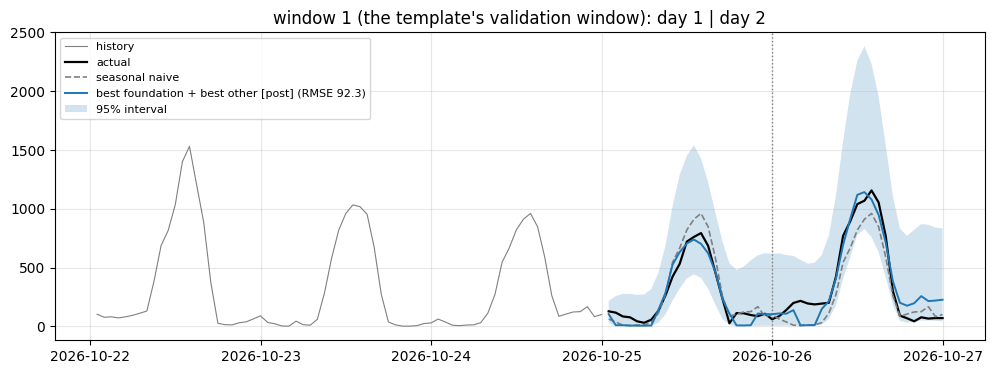

ds,2026-10-27 01:00:00,2026-10-27 02:00:00,2026-10-27 03:00:00,2026-10-27 04:00:00,2026-10-27 05:00:00,2026-10-27 06:00:00,2026-10-27 07:00:00,2026-10-27 08:00:00,2026-10-27 09:00:00,2026-10-27 10:00:00,...,2026-10-28 15:00:00,2026-10-28 16:00:00,2026-10-28 17:00:00,2026-10-28 18:00:00,2026-10-28 19:00:00,2026-10-28 20:00:00,2026-10-28 21:00:00,2026-10-28 22:00:00,2026-10-28 23:00:00,2026-10-29 00:00:00
forecast,100.3,9.6,9.6,8.8,102.2,101.9,123.7,194.2,355.3,628.9,...,753.7,440.7,221.5,122.5,119.8,9.6,100.7,9.1,101.8,8.4
lower_95,32.8,9.6,9.6,8.8,9.9,7.3,9.9,34.7,98.3,202.4,...,378.1,203.8,52.0,3.3,0.0,0.0,0.0,0.1,0.0,0.0
upper_95,226.3,324.3,389.5,415.6,430.8,438.5,460.6,626.4,892.4,1215.7,...,1694.7,1306.7,904.5,656.5,609.8,602.6,607.1,603.5,599.7,605.6


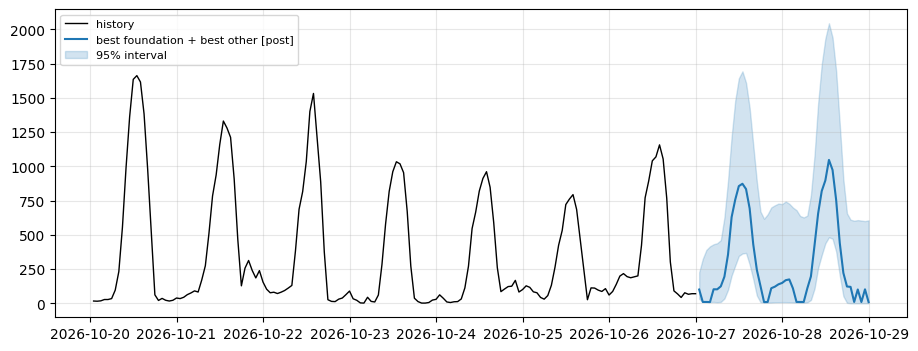

[20.2 min since the start of Section 2]


In [26]:
pool = list(scoreboard.drop(index="benchmark").index[:12])
bench_w = scoreboard.loc["benchmark", "Winkler"]
rows = []
for n in pool:
    chk = interval_check(n)                                      # day 2, purged
    rec = chk["Winkler"].idxmin()
    rows.append({"model": n, "interval": rec, "RMSE skill": scoreboard.loc[n, "RMSE skill"],
                 "MAPE skill": scoreboard.loc[n, "MAPE skill"], "Winkler skill": chk.loc[rec, "Winkler"] / bench_w,
                 "coverage": chk.loc[rec, "coverage"], "beat bench": scoreboard.loc[n, "beat bench"]})
ranking = pd.DataFrame(rows).set_index("model")
ranking["ranking score"] = 0.3 * ranking["RMSE skill"] + 0.3 * ranking["MAPE skill"] + 0.4 * ranking["Winkler skill"]
ranking = ranking.sort_values("ranking score")


def rmse_skill_on(windows):
    # day-2 RMSE skill of every ranked model on some of the windows only
    rows_ = _part(bt[bt["window"].isin(windows)])
    ref = _per_window(rows_, rows_["benchmark"])[0].mean()
    return pd.Series({n: _per_window(rows_, rows_[n])[0].mean() / ref for n in ranking.index})


RECENT = range(1, 6)              # the five most recent windows: the level fell sharply in the last week of October
ranking["RMSE skill, recent 5"] = rmse_skill_on(RECENT)
ranking["RMSE skill, other 15"] = rmse_skill_on([w for w in range(1, WINDOWS + 1) if w not in RECENT])
print("the recent windows cover", dates.iloc[len(y) - (max(RECENT) - 1) * STEP - H], "to", dates.iloc[len(y) - 1])
display(ranking.round(3))

CHOICE = ranking.index[0]                                        # <-- or any row you can defend
INTERVAL = ranking.loc[CHOICE, "interval"]
# The interval of the choice: every recipe on the held-out windows; the one with the lowest Winkler is used. (The median
# of the 3 best intervals ties the own interval here: 979 vs 979 on day 2, and it was 2% worse on day 1.)
interval_table = interval_check(CHOICE)
interval_table["Winkler skill"] = interval_table["Winkler"] / bench_w
print(f"interval recipes for {CHOICE} (day 2, held-out windows):")
display(interval_table.round(3))
ranking.loc[CHOICE, "interval"] = INTERVAL
ranking.loc[CHOICE, "Winkler skill"] = interval_table.loc[INTERVAL, "Winkler skill"]
ranking.loc[CHOICE, "coverage"] = interval_table.loc[INTERVAL, "coverage"]
ranking.loc[CHOICE, "ranking score"] = (0.3 * ranking.loc[CHOICE, "RMSE skill"] + 0.3 * ranking.loc[CHOICE, "MAPE skill"]
                                        + 0.4 * ranking.loc[CHOICE, "Winkler skill"])
print(f"CHOICE = {CHOICE}, interval = {INTERVAL}: day-2 RMSE skill {ranking.loc[CHOICE, 'RMSE skill']:.3f}, "
      f"MAPE skill {ranking.loc[CHOICE, 'MAPE skill']:.3f}, Winkler skill {ranking.loc[CHOICE, 'Winkler skill']:.3f}, "
      f"beat the benchmark in {ranking.loc[CHOICE, 'beat bench']} of {WINDOWS} windows")

# the template's validation window (window 1): the choice and the best few next to the benchmark
g, o = bt[bt["window"] == 1], others(1)
for name in list(dict.fromkeys([CHOICE] + list(ranking.index[:5]))):
    if g[f"{name} lo"].notna().all():
        lo, hi = g[f"{name} lo"], g[f"{name} hi"]
    else:
        lo, hi = _bounds(g[name], g["daylight"], _radius(o["actual"], o[name], o["daylight"], "conformal day/night"), "conformal day/night")
    results.loc[name] = score(valid, g[name], lo, hi)
display(results)
plot_validation([CHOICE])

FINAL_FORECAST = final_forecast(CHOICE, INTERVAL)     # (forecast, lower_95, upper_95) from the whole history
final_view = pd.DataFrame(dict(zip(["forecast", "lower_95", "upper_95"], FINAL_FORECAST)), index=FUTURE)
display(final_view.round(1).T)
fig, ax = plt.subplots()
ax.plot(dates.iloc[-7 * DAY:], y[-7 * DAY:], color="black", lw=1, label="history")
ax.plot(FUTURE, final_view["forecast"], color="tab:blue", label=CHOICE)
ax.fill_between(FUTURE, final_view["lower_95"], final_view["upper_95"], color="tab:blue", alpha=0.2, label="95% interval")
ax.legend(loc="upper left", fontsize=8)
plt.show()
elapsed()

In [27]:
# Saved for the report (LUKIANETS_report.ipynb): the scoreboards, the ranking, the interval recipes of the choice and
# the choice's rolling-window rows with its members
Path(RESULTS_DIR).mkdir(exist_ok=True)
scoreboard.to_csv(f"{RESULTS_DIR}/scoreboard_day2.csv")
window_table(part="all").to_csv(f"{RESULTS_DIR}/scoreboard_all48.csv")
ranking.to_csv(f"{RESULTS_DIR}/ranking.csv")
interval_table.to_csv(f"{RESULTS_DIR}/interval_recipes.csv")
pd.Series(FAMILY, name="family").rename_axis("model").to_csv(f"{RESULTS_DIR}/families.csv")
base = POST[CHOICE]["day"] if CHOICE in POST else CHOICE
members = list(MIXES[base][0]) if base in MIXES else []
keep = [c for n in dict.fromkeys([CHOICE, base] + members) for c in (n, f"{n} lo", f"{n} hi") if c in bt.columns]
bt[list(BASE_COLS) + keep].to_csv(f"{RESULTS_DIR}/final_model_bt.csv", index=False)
pd.Series({"choice": CHOICE, "interval": INTERVAL, "base": base, "members": " | ".join(members),
           "night rule a": POST.get(CHOICE, {}).get("a"), "night rule level": POST.get(CHOICE, {}).get("level")},
          name="value").to_csv(f"{RESULTS_DIR}/choice.csv")
print("saved for the report:", sorted(p.name for p in Path(RESULTS_DIR).glob("*.csv") if not p.name.startswith(("colab", "family_"))))

saved for the report: ['choice.csv', 'families.csv', 'final_model_bt.csv', 'interval_recipes.csv', 'ranking.csv', 'scoreboard_all48.csv', 'scoreboard_day2.csv']


### 2.14 After the public leaderboard: the midday lower bound on day 2

The public leaderboard of Thursday 5 November scored the first 24 hidden hours (27 October) of the file made by 2.13:
RMSE 81.7 and MAPE 38.2% against the seasonal naive's 115.7 and 84.3%, but a **Winkler score of 741 against 521**.
Every hour fell inside both intervals, so each Winkler score is simply the mean width, and ours was the wider one. The
rolling windows had warned about this: in the five most recent, calm windows the interval covered every hour and its
Winkler skill was 0.91. On day 2 the seasonal naive's interval is 697 wide on average, ours 880.

**Where the width can go without new risk.** In the lit hours 09:00–14:00 of day 2 the actual output never came close
to the lower bound in any window: at most 0.56 of the way from the point to the bound. The upper side and the night
carry the real risks (the misses of 2.13 are bright days and windy nights), and 28 October is forecast drier than the
foggy week before it, the regime where the model's misses fall above. **The rule:** on day 2, in the lit hours
09:00–14:00, the lower bound moves to *point − 0.7 · (point − lower bound)*. The factor is a round step with room to
spare (0.7 against the 0.56 seen), not tuned on the public score, and the hours around sunrise and sunset keep their
bounds because of the clock change. It applies to day 2 only: day 1 is already scored, and on day 1 of the windows it
would have added 4 misses below. Narrowing the upper side or the night as well was rejected: it gains about 50 in
most windows and loses about 900 in each of the two with windy nights (16–17 October). The report also checks the
rule against the last 21 real days as possible outcomes for 28 October, on the old and the new clock.

In [28]:
# The public leaderboard, 5 November 09:00: the first 24 hidden hours (27 October), scored on the file from 2.13
public = pd.DataFrame({"RMSE": [81.7, 115.7], "MAPE": [38.2, 84.3], "Winkler": [741, 521], "coverage": [1.0, 1.0]},
                      index=["this model (2.13)", "seasonal naive"])
display(public)

MIDDAY, SHRINK = range(9, 15), 0.7          # lit hours 09:00-14:00 of day 2: lower bound -> point - 0.7 (point - lower)


def winkler_by_window(frame, lo, hi):
    a = frame["actual"].to_numpy()
    w = (hi - lo) + 2 / 0.05 * (np.clip(lo - a, 0, None) + np.clip(a - hi, 0, None))
    return pd.Series(w, index=frame.index).groupby(frame["window"]).mean()


# the rule on the rolling windows: each day of the windows, before and after
check = []
for day in (1, 2):
    part = bt[(bt["step"] > DAY) == (day == 2)]
    t = len(y) - (part["window"] - 1) * STEP - H + part["step"] - 1
    hours = dates.iloc[t].dt.hour.to_numpy()
    point, lo, hi = (part[c].to_numpy() for c in (CHOICE, f"{CHOICE} lo", f"{CHOICE} hi"))
    core = (part["daylight"].to_numpy() == 1) & np.isin(hours, list(MIDDAY))
    lo_new = np.where(core, point - SHRINK * (point - lo), lo)
    before, after = winkler_by_window(part, lo, hi), winkler_by_window(part, lo_new, hi)
    bench = winkler_by_window(part, part["benchmark lo"].to_numpy(), part["benchmark hi"].to_numpy())
    a = part["actual"].to_numpy()
    check.append({"day": day, "Winkler skill before": before.mean() / bench.mean(), "Winkler skill after": after.mean() / bench.mean(),
                  "windows better": int((after < before - 1e-9).sum()), "windows worse": int((after > before + 1e-9).sum()),
                  "misses below before": int((a < lo).sum()), "misses below after": int((a < lo_new).sum()),
                  "closest approach to the midday lower bound": ((point - a)[core] / (point - lo)[core]).max()})
display(pd.DataFrame(check).set_index("day").round(3))

# the rule on the submission: day 2 only
point, lo, hi = FINAL_FORECAST
core = (np.arange(H) >= DAY) & (weather_fc["daylight"].to_numpy()[:H] == 1) & np.isin(FUTURE.dt.hour.to_numpy(), list(MIDDAY))
lo_new = np.where(core, point - SHRINK * (point - lo), lo)
change = pd.DataFrame({"forecast": point, "lower before": lo, "lower after": lo_new, "upper": hi, "changed": core},
                      index=FUTURE.to_numpy())
display(change[core].round(1))
print(f"day-2 mean width {np.mean((hi - lo)[DAY:]):.0f} -> {np.mean((hi - lo_new)[DAY:]):.0f}; day 1 unchanged")
public.to_csv(f"{RESULTS_DIR}/public_board.csv")
change.rename_axis("ds").to_csv(f"{RESULTS_DIR}/day2_midday_lower.csv")
FINAL_FORECAST = (point, lo_new, hi)

,RMSE,MAPE,Winkler,coverage
this model (2.13),81.7,38.2,741,1.0
seasonal naive,115.7,84.3,521,1.0


,Winkler skill before,Winkler skill after,windows better,windows worse,misses below before,misses below after,closest approach to the midday lower bound
day,,,,,,,
1,0.295,0.290,19,1,3,7,1.464
2,0.357,0.343,20,0,1,1,0.557


,forecast,lower before,lower after,upper,changed
2026-10-28 09:00:00,423.1,107.8,202.4,1079.5,True
2026-10-28 10:00:00,655.5,258.4,377.6,1457.7,True
2026-10-28 11:00:00,819.3,351.8,492.0,1743.5,True
2026-10-28 12:00:00,896.4,437.6,575.3,1931.3,True
2026-10-28 13:00:00,1046.5,482.1,651.4,2043.9,True
2026-10-28 14:00:00,973.3,471.4,621.9,1939.5,True


day-2 mean width 880 -> 846; day 1 unchanged


**Justification** — the EDA (2.1); the scale (2.2); the best ETS and the training length it needs (2.5); the ARIMA
reading, the grid and what the weather added (2.6); Prophet and LightGBM (2.7–2.8); the foundation / neural models
(2.10); the choice, its skill against the seasonal naive on RMSE, MAPE and Winkler, in how many windows it won, and
the interval with its coverage on unseen windows.

→

## 3. Submission

Replace the benchmark in the first line with your own forecast. `forecast`, `lower_95` and `upper_95`
are arrays of 48 numbers, one for each hour in `FUTURE`, in order. Generation cannot be negative, so the
lower bound must be 0 or above.

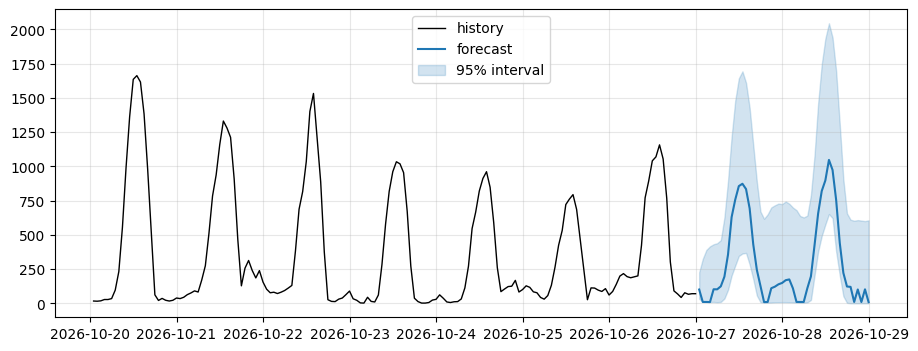

In [29]:
forecast, lower_95, upper_95 = FINAL_FORECAST if "FINAL_FORECAST" in globals() else snaive(y)   # <-- Sections 2.13-2.14

fig, ax = plt.subplots()
ax.plot(data["ds"].iloc[-7 * M:], y[-7 * M:], color="black", lw=1, label="history")
ax.plot(FUTURE, forecast, color="tab:blue", label="forecast")
ax.fill_between(FUTURE, lower_95, upper_95, color="tab:blue", alpha=0.2, label="95% interval")
ax.legend()
plt.show()

In [30]:
def check_submission(sub: pd.DataFrame) -> None:
    assert list(sub.columns) == ["ds", "forecast", "lower_95", "upper_95"], "wrong columns"
    assert len(sub) == H, f"need {H} rows, got {len(sub)}"
    assert (pd.to_datetime(sub["ds"]).to_numpy() == FUTURE.to_numpy()).all(), "the hours do not match FUTURE"
    assert sub[["forecast", "lower_95", "upper_95"]].notna().all().all(), "missing values"
    assert (sub["lower_95"] >= 0).all(), "a lower bound is negative"
    assert (sub["lower_95"] <= sub["forecast"]).all() and (sub["forecast"] <= sub["upper_95"]).all(), \
        "the forecast must lie inside its interval"
    print("format OK")


submission = pd.DataFrame({"ds": FUTURE.dt.strftime("%Y-%m-%d %H:%M:%S"), "forecast": forecast,
                           "lower_95": lower_95, "upper_95": upper_95})
check_submission(submission)

FILE = f"{SURNAME.strip().upper()}_project.csv"
submission.to_csv(FILE, index=False)
print("saved", FILE)

try:
    from google.colab import files
    files.download(FILE)
except ImportError:
    pass

format OK
saved LUKIANETS_project.csv


Upload `SURNAME_project.csv` to the *Session 1* activity on Moodle by **11:30**. You can upload more than
once, and the last file before 11:30 counts, so submit the benchmark early and replace it if you find
something better.

After the session you can keep working on the forecast at home. The project description on Moodle has
the details.